# **Explainable Phishing URL Detection Using Machine Learning and SHAP**

**Project stage:** Dataset understanding, preprocessing, feature engineering, exploratory data analysis (EDA), baseline model training, hyperparameter tuning, model evaluation, SHAP explanations, a robustness check and the conclusion.

**Project overview**

Phishing websites attempt to trick users into revealing passwords, financial details, or other sensitive information. This project investigates how characteristics extracted from URLs can help distinguish phishing websites from legitimate websites. Five machine learning models, including a neural network, are compared and SHAP is used to explain their predictions.

**Research questions**

- **RQ1:** How accurately can machine learning classifiers distinguish phishing URLs from legitimate URLs using the Kaitholikkal and Arthi phishing URL dataset?
- **RQ2:** Which lexical and structural URL characteristics are identified by SHAP as the most influential factors in distinguishing phishing URLs from legitimate URLs?
- **RQ3:** Which machine learning model provides the best performance in accuracy, precision, recall, F1-score and ROC-AUC?

This notebook prepares the data, trains baseline models, tunes and retrains them, compares both sets of results and uses SHAP to explain the predictions. It then checks how much the results depend on the protocol and ends with a conclusion that answers the research questions.

## **Dataset Description**

**Source:** Kaitholikkal and Arthi, *Phishing URL Dataset*, Mendeley Data (2024), version 1.  
**DOI:** [10.17632/vfszbj9b36.1](https://doi.org/10.17632/vfszbj9b36.1)

The repository contains two CSV files supplied with this project:

| CSV file | Rows verified | URL field | Label field | Label values |
|---|---:|---|---|---|
| `URL dataset.csv` | 450,176 | `url` | `type` | `legitimate`, `phishing` |
| `Phishing URLs.csv` | 54,807 | `url` | `Type` | `Phishing` |

The main dataset contains **345,738 legitimate** and **104,438 phishing** URLs. The separate file contains **only phishing URLs**, so it cannot be used alone for binary classification. We load and inspect both datasets, then combine them into one working dataset. After duplicate URLs are removed it holds **504,932 unique URLs**: 345,738 legitimate and 159,194 phishing.

**Input files:** Put both CSV files in the **same folder** as this notebook before running it.

**Labels used throughout:** `0 = legitimate`, `1 = phishing`.

## **Import Libraries**

**Purpose:** Load the Python libraries used for data processing, charts and URL parsing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import urlsplit
from collections import Counter

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## **Load Both Datasets**

**Purpose:** Read the two named CSV files directly. No automatic file searches or alternative filenames are used.

In [2]:
import pandas as pd

# Load both datasets
url_df = pd.read_csv("URL dataset.csv")
phishing_df = pd.read_csv("Phishing URLs.csv")

# Standardize column names
url_df.columns = url_df.columns.str.lower()
phishing_df.columns = phishing_df.columns.str.lower()

# Combine both datasets
combined_df = pd.concat(
    [url_df, phishing_df],
    ignore_index=True
)

# Standardize labels
combined_df["type"] = combined_df["type"].str.strip().str.lower()

# Check duplicates
print("Duplicate URLs:", combined_df["url"].duplicated().sum())

# Check conflicting labels for the same URL
conflicts = combined_df.groupby("url")["type"].nunique()
print("URLs with conflicting labels:", (conflicts > 1).sum())

# Check combined dataset
print("\nCombined Dataset Shape:", combined_df.shape)

print("\nClass Distribution:")
display(combined_df["type"].value_counts(dropna=False))

Duplicate URLs: 50
URLs with conflicting labels: 0

Combined Dataset Shape: (504983, 2)

Class Distribution:


type
legitimate    345738
phishing      159245
Name: count, dtype: int64

### **Check the Original Datasets**

**Purpose:** Reload the two original CSV files and look at their shapes and label counts on their own, before they are joined into the working dataset.

In [3]:
import pandas as pd

# Load original datasets
url_df = pd.read_csv("URL dataset.csv")
phishing_df = pd.read_csv("Phishing URLs.csv")

# Check dataset shapes
print("Main Dataset Shape:", url_df.shape)
print("Phishing Dataset Shape:", phishing_df.shape)

# Check class distribution
print("\nMain Dataset Labels:")
display(url_df["type"].value_counts(dropna=False))

print("\nPhishing-only Dataset Labels:")
display(phishing_df["Type"].value_counts(dropna=False))

Main Dataset Shape: (450176, 2)
Phishing Dataset Shape: (54807, 2)

Main Dataset Labels:


type
legitimate    345738
phishing      104438
Name: count, dtype: int64


Phishing-only Dataset Labels:


Type
Phishing    54807
Name: count, dtype: int64

## **Inspect Dataset Columns**

**Purpose:** Check the column names and data types in each file. The second file uses `Type` with a capital letter.

In [4]:
print("Main dataset columns:", url_df.columns.tolist())
print("Phishing-only dataset columns:", phishing_df.columns.tolist())
print("\nMain dataset types:")
print(url_df.dtypes)
print("\nPhishing-only dataset types:")
print(phishing_df.dtypes)

Main dataset columns: ['url', 'type']
Phishing-only dataset columns: ['url', 'Type']

Main dataset types:
url     object
type    object
dtype: object

Phishing-only dataset types:
url     object
Type    object
dtype: object


## **Compare Dataset Labels**

**Purpose:** Confirm the observed label values and their frequencies in each CSV before preparing the main dataset.

In [5]:
print("Main dataset labels:")
display(url_df["type"].value_counts(dropna=False))

print("Phishing-only dataset labels:")
display(phishing_df["Type"].value_counts(dropna=False))

Main dataset labels:


type
legitimate    345738
phishing      104438
Name: count, dtype: int64

Phishing-only dataset labels:


Type
Phishing    54807
Name: count, dtype: int64

## **Inspect Missing Values and Duplicates**

**Purpose:** Count missing cells and repeated URLs in both files. This inspection does not change either dataset.

In [6]:
print("Missing values in main dataset:")
display(url_df.isna().sum())
print("Duplicate URLs in main dataset:", url_df["url"].duplicated().sum())

print("\nMissing values in phishing-only dataset:")
display(phishing_df.isna().sum())
print("Duplicate URLs in phishing-only dataset:", phishing_df["url"].duplicated().sum())

Missing values in main dataset:


url     0
type    0
dtype: int64

Duplicate URLs in main dataset: 0

Missing values in phishing-only dataset:


url     0
Type    0
dtype: int64

Duplicate URLs in phishing-only dataset: 2


## **Check Whether the Files Overlap**

**Purpose:** Count URLs from the phishing-only file that also occur in the main dataset. These repeated URLs are removed as duplicates once the two files are combined.

In [7]:
overlap_count = phishing_df["url"].isin(url_df["url"]).sum()
print("Rows in phishing-only file also appearing in main dataset:", overlap_count)
print("Unique overlapping URLs:", phishing_df.loc[phishing_df["url"].isin(url_df["url"]), "url"].nunique())

Rows in phishing-only file also appearing in main dataset: 48
Unique overlapping URLs: 48


## **Create the Working Dataset**

**Purpose:** Join the two files into one working dataset and remove duplicate rows. The original files are left unchanged, and the combined dataset is used for the remaining analysis.

In [8]:

# Combine both datasets
df = pd.concat(
    [
        url_df.rename(columns={'type': 'type'}),
        phishing_df.rename(columns={'Type': 'type'})
    ],
    ignore_index=True
)

# Standardize class labels
df['type'] = df['type'].str.strip().str.lower()

# Display shape before removing duplicates
print("Dataset Shape Before Removing Duplicates:", df.shape)

# Count duplicate rows
print("Total Duplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Display shape after removing duplicates
print("\nDataset Shape After Removing Duplicates:", df.shape)

# Display class distribution
print("\nClass Distribution:")
display(df['type'].value_counts(dropna=False))

# Display first 5 rows
display(df.head())

Dataset Shape Before Removing Duplicates: (504983, 2)
Total Duplicate Rows: 50

Dataset Shape After Removing Duplicates: (504933, 2)

Class Distribution:


type
legitimate    345738
phishing      159195
Name: count, dtype: int64

,url,type
0,https://www.google.com,legitimate
1,https://www.youtube.com,legitimate
2,https://www.facebook.com,legitimate
3,https://www.baidu.com,legitimate
4,https://www.wikipedia.org,legitimate


## **Clean URLs and Labels**

**Purpose:** Strip unwanted spaces, convert labels to lowercase and remove missing or duplicate records. Only two labels are valid in the observed main dataset.

In [9]:
df["url"] = df["url"].astype("string").str.strip()
df["type"] = df["type"].astype("string").str.strip().str.lower()

print("Rows before cleaning:", len(df))
df = df.dropna(subset=["url", "type"])
df = df[df["url"] != ""].copy()
df = df.drop_duplicates(subset=["url"]).reset_index(drop=True)

print("Rows after cleaning:", len(df))
print("Labels after cleaning:")
print(df["type"].value_counts(dropna=False))

Rows before cleaning: 504933
Rows after cleaning: 504932
Labels after cleaning:
type
legitimate    345738
phishing      159194
Name: count, dtype: Int64


## **Encode the Target Labels**

**Purpose:** Convert the two verified text labels to integers: **legitimate = 0** and **phishing = 1**.

In [10]:
label_mapping = {"legitimate": 0, "phishing": 1}
df["label"] = df["type"].map(label_mapping).astype("int64")

print("Encoded label counts:")
display(df["label"].value_counts().sort_index())
display(df.head())

Encoded label counts:


label
0    345738
1    159194
Name: count, dtype: int64

,url,type,label
0,https://www.google.com,legitimate,0
1,https://www.youtube.com,legitimate,0
2,https://www.facebook.com,legitimate,0
3,https://www.baidu.com,legitimate,0
4,https://www.wikipedia.org,legitimate,0


## **Explore Class Balance**

**Purpose:** Visualize the number and percentage of legitimate and phishing URLs. An imbalanced dataset requires appropriate evaluation metrics during later modelling.

Class percentages:


type
legitimate    68.47
phishing      31.53
Name: count, dtype: Float64

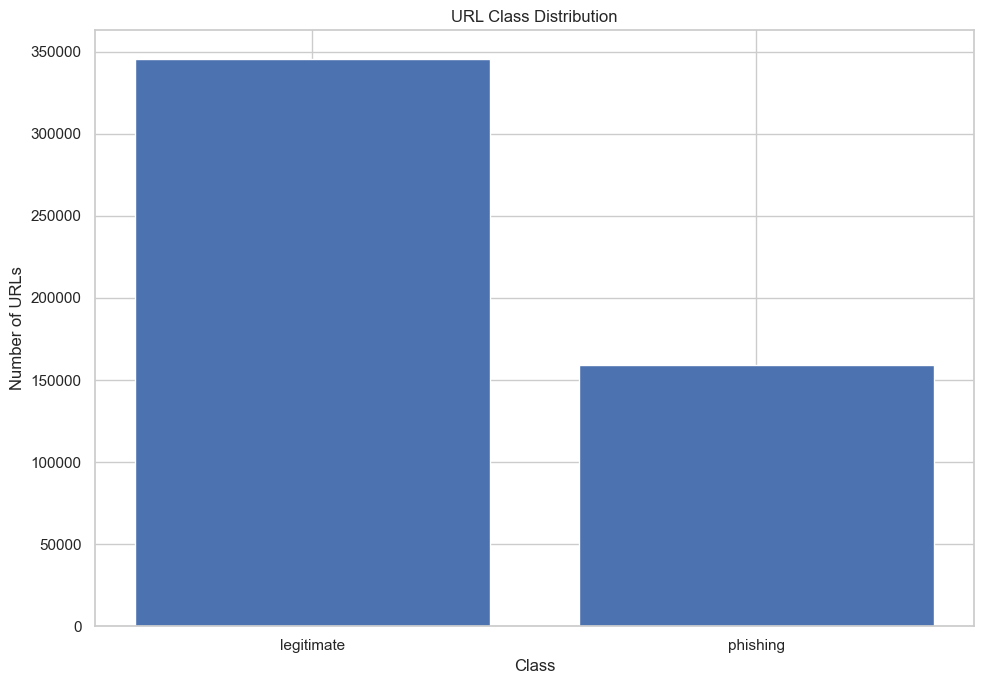

In [11]:
counts = df["type"].value_counts().reindex(["legitimate", "phishing"])
print("Class percentages:")
display((counts / len(df) * 100).round(2))

plt.figure(figsize=(10, 7))
plt.bar(counts.index, counts.values)
plt.title("URL Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of URLs")
plt.tight_layout()
plt.show()

## **Extract Basic URL Features**

**Purpose:** Turn URL text into measurable numerical characteristics. These are lexical and structural indicators, **not** proof of phishing on their own.

**Extracted features:** URL length, number of dots, hyphens, digits, slashes, question marks, equals signs, at signs, percent signs, ampersands, HTTPS usage and HTTP usage.

In [12]:
df["url_length"] = df["url"].str.len()
df["dot_count"] = df["url"].str.count(r"\.")
df["hyphen_count"] = df["url"].str.count("-")
df["digit_count"] = df["url"].str.count(r"\d")
df["slash_count"] = df["url"].str.count("/")
df["question_count"] = df["url"].str.count(r"\?")
df["equal_count"] = df["url"].str.count("=")
df["at_count"] = df["url"].str.count("@")
df["percent_count"] = df["url"].str.count("%")
df["ampersand_count"] = df["url"].str.count("&")
df["uses_https"] = df["url"].str.lower().str.startswith("https://").astype(int)
df["uses_http"] = df["url"].str.lower().str.startswith("http://").astype(int)

display(df.head())

,url,type,label,url_length,dot_count,hyphen_count,digit_count,slash_count,question_count,equal_count,at_count,percent_count,ampersand_count,uses_https,uses_http
0,https://www.google.com,legitimate,0,22,2,0,0,2,0,0,0,0,0,1,0
1,https://www.youtube.com,legitimate,0,23,2,0,0,2,0,0,0,0,0,1,0
2,https://www.facebook.com,legitimate,0,24,2,0,0,2,0,0,0,0,0,1,0
3,https://www.baidu.com,legitimate,0,21,2,0,0,2,0,0,0,0,0,1,0
4,https://www.wikipedia.org,legitimate,0,25,2,0,0,2,0,0,0,0,0,1,0


## **Extract Hostname and Path Features**

**Purpose:** Separate each URL into its hostname, path and query using Python's URL parser. For parsing, URLs without a scheme are prefixed with `//`, which treats their first component as a hostname. This changes only the parsing input, not the original URL.

A simple `subdomain_parts` feature counts hostname segments before the last two segments; it is an approximation, **not** a public-suffix-aware domain parser (e.g., `co.uk` needs different handling).

In [13]:
def parse_url(url):
    text = str(url)
    try:
        parsed = urlsplit(text if "://" in text else "//" + text)
        return parsed.hostname or "", parsed.path, parsed.query
    except ValueError:
        return "", text, ""

parsed_columns = pd.DataFrame(
    [parse_url(url) for url in df["url"]],
    columns=["hostname", "path", "query"]
)
df = pd.concat([df, parsed_columns], axis=1)

df["hostname_length"] = df["hostname"].str.len()
df["path_length"] = df["path"].str.len()
df["query_length"] = df["query"].str.len()
df["hostname_dot_count"] = df["hostname"].str.count(r"\.")
df["subdomain_parts"] = (df["hostname_dot_count"] - 1).clip(lower=0)

display(df[["url", "hostname", "path", "query", "hostname_length", "path_length", "subdomain_parts"]].head())

,url,hostname,path,query,hostname_length,path_length,subdomain_parts
0,https://www.google.com,www.google.com,,,14,0,1
1,https://www.youtube.com,www.youtube.com,,,15,0,1
2,https://www.facebook.com,www.facebook.com,,,16,0,1
3,https://www.baidu.com,www.baidu.com,,,13,0,1
4,https://www.wikipedia.org,www.wikipedia.org,,,17,0,1


## **Check Engineered Features**

**Purpose:** Confirm that numerical features have been created and review summary statistics before plotting.

In [14]:
feature_columns = [
    "url_length", "dot_count", "hyphen_count", "digit_count", "slash_count",
    "question_count", "equal_count", "at_count", "percent_count",
    "ampersand_count", "uses_https", "uses_http", "hostname_length",
    "path_length", "query_length", "hostname_dot_count", "subdomain_parts"
]
print("Number of engineered features:", len(feature_columns))
display(df[feature_columns].describe().T)
print("Missing engineered values:", df[feature_columns].isna().sum().sum())

Number of engineered features: 17


,count,mean,std,min,25%,50%,75%,max
url_length,504932.0,60.925033,66.309998,8.0,39.0,52.0,71.0,25523.0
dot_count,504932.0,2.582074,1.166874,0.0,2.0,2.0,3.0,40.0
hyphen_count,504932.0,1.205346,2.483497,0.0,0.0,0.0,1.0,88.0
digit_count,504932.0,4.521326,11.973747,0.0,0.0,1.0,6.0,3413.0
slash_count,504932.0,4.36048,1.591545,2.0,3.0,4.0,5.0,104.0
question_count,504932.0,0.150295,0.454316,0.0,0.0,0.0,0.0,166.0
equal_count,504932.0,0.270072,1.068434,0.0,0.0,0.0,0.0,131.0
at_count,504932.0,0.00766,0.099175,0.0,0.0,0.0,0.0,11.0
percent_count,504932.0,0.089046,1.168927,0.0,0.0,0.0,0.0,134.0
ampersand_count,504932.0,0.135464,0.852835,0.0,0.0,0.0,0.0,50.0


Missing engineered values: 0


## **Compare Feature Averages Across Classes**

**Purpose:** Compare basic URL properties for phishing and legitimate classes.

In [15]:
features_to_compare = ["url_length", "hostname_length", "path_length", "digit_count", "dot_count", "hyphen_count", "subdomain_parts"]
display(df.groupby("type")[features_to_compare].mean().round(2).T)

type,legitimate,phishing
url_length,58.48,66.23
hostname_length,19.62,20.88
path_length,27.58,25.57
digit_count,3.28,7.23
dot_count,2.65,2.43
hyphen_count,1.46,0.65
subdomain_parts,1.28,0.72


## **Visualize URL Length**

**Purpose:** Compare URL-length distributions by class. The graph is limited to the 99th percentile of URL length to keep extreme values from hiding the main distribution; no rows are removed from the dataset.

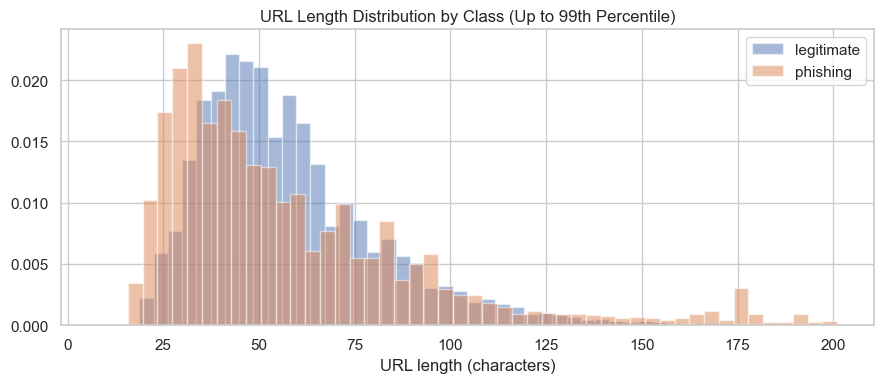

In [16]:
upper_length = df["url_length"].quantile(0.99)
plt.figure(figsize=(9, 4))
for label in ["legitimate", "phishing"]:
    values = df.loc[(df["type"] == label) & (df["url_length"] <= upper_length), "url_length"]
    plt.hist(values, bins=50, density=True, alpha=0.5, label=label)
plt.title("URL Length Distribution by Class (Up to 99th Percentile)")
plt.xlabel("URL length (characters)")
plt.legend()
plt.tight_layout()
plt.show()

## **Visualize URL Length by Class**

**Purpose:** Display a boxplot to compare the median and spread of URL lengths without the top 1% of values obscuring the chart.

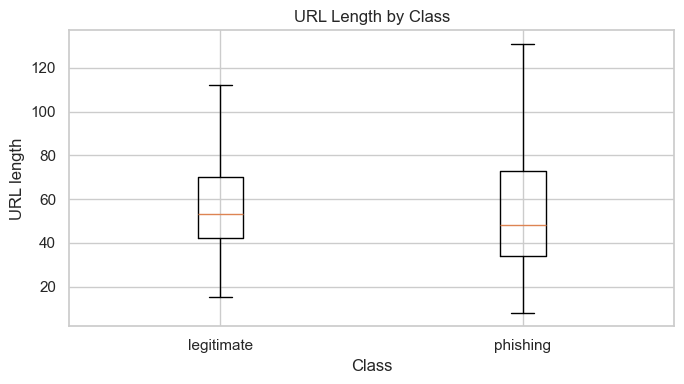

In [17]:
plt.figure(figsize=(7, 4))
values = [df.loc[(df["type"] == label) & (df["url_length"] <= upper_length), "url_length"] for label in ["legitimate", "phishing"]]
plt.boxplot(values, tick_labels=["legitimate", "phishing"], showfliers=False)
plt.title("URL Length by Class")
plt.xlabel("Class")
plt.ylabel("URL length")
plt.tight_layout()
plt.show()

## **Visualize Digit Counts**

**Purpose:** Compare how frequently numerical digits appear in URLs for each class.

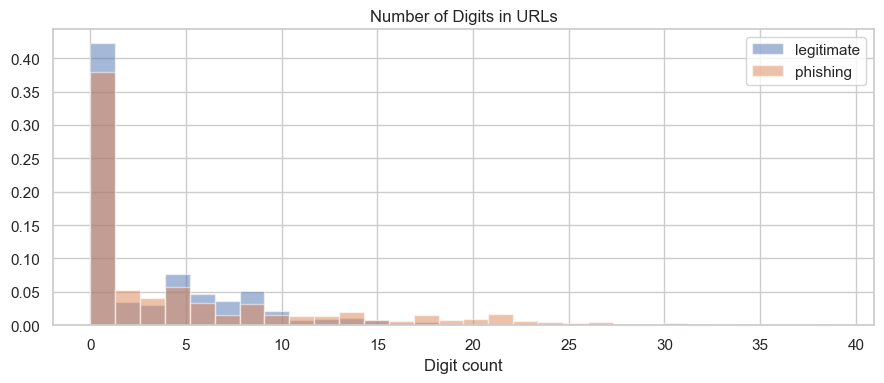

In [18]:
digit_limit = df["digit_count"].quantile(0.99)
plt.figure(figsize=(9, 4))
for label in ["legitimate", "phishing"]:
    values = df.loc[(df["type"] == label) & (df["digit_count"] <= digit_limit), "digit_count"]
    plt.hist(values, bins=30, density=True, alpha=0.5, label=label)
plt.title("Number of Digits in URLs")
plt.xlabel("Digit count")
plt.legend()
plt.tight_layout()
plt.show()

## **Compare HTTPS Usage**

**Purpose:** Show the proportion of each class that begins with `https://`. HTTPS alone does not demonstrate that a website is legitimate.

Percentage of HTTPS URLs by class:


type
legitimate    99.99
phishing      34.88
Name: uses_https, dtype: float64

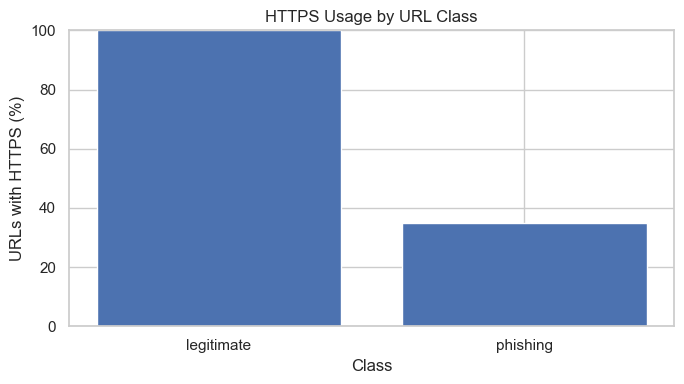

In [19]:
https_by_class = df.groupby("type")["uses_https"].mean().mul(100).round(2)
print("Percentage of HTTPS URLs by class:")
display(https_by_class)

plt.figure(figsize=(7, 4))
plt.bar(https_by_class.index, https_by_class.values)
plt.title("HTTPS Usage by URL Class")
plt.xlabel("Class")
plt.ylabel("URLs with HTTPS (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## **Explore Feature Correlations**

**Purpose:** Visualize relationships among extracted URL features and the binary target. Correlation shows association, not causation.

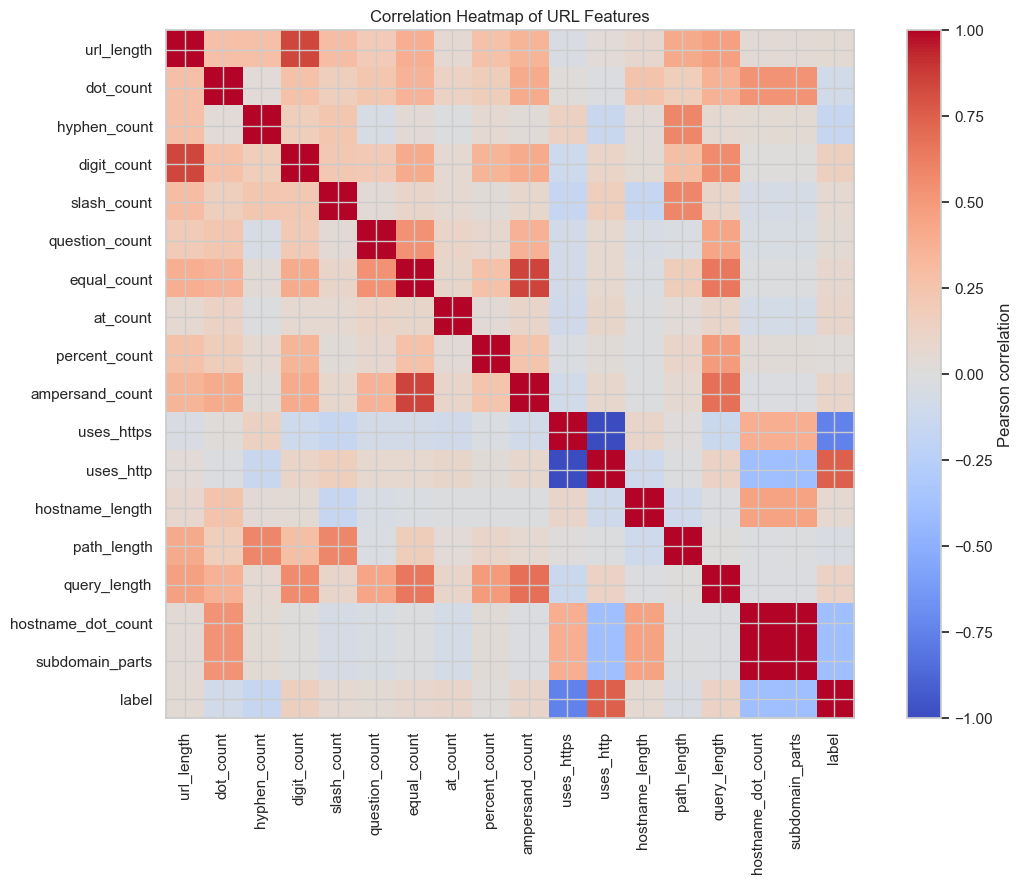

In [20]:
correlations = df[feature_columns + ["label"]].corr()
plt.figure(figsize=(12, 9))
plt.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(correlations.columns)), correlations.columns, rotation=90)
plt.yticks(range(len(correlations.index)), correlations.index)
plt.title("Correlation Heatmap of URL Features")
plt.tight_layout()
plt.show()

## **Save the Processed Dataset**

**Purpose:** Save the cleaned dataset with all engineered features to a new CSV file, so the processed data can be reused without repeating the steps above.

In [21]:
df.to_csv("phishing_urls_processed.csv", index=False)
print("Saved: phishing_urls_processed.csv")
print("Final dataset shape:", df.shape)
print("Class distribution:")
print(df["label"].value_counts().sort_index())

Saved: phishing_urls_processed.csv
Final dataset shape: (504932, 23)
Class distribution:
label
0    345738
1    159194
Name: count, dtype: int64


# **Machine Learning Modelling**

This part of the notebook answers the research questions. Several machine learning models are trained on the engineered URL features, their performance is compared, and SHAP is used to explain which URL characteristics drive the predictions.

**Models used in this project:**

- **Logistic Regression** – a simple linear baseline model
- **Decision Tree** – an easy to interpret rule based model
- **Random Forest** – many decision trees combined together
- **XGBoost** – a powerful gradient boosting model
- **Neural Network (MLP)** – a multi-layer perceptron that learns non-linear patterns through hidden layers

## **Install Extra Libraries**

**Purpose:** Install the `xgboost` and `shap` libraries. They are used for the boosting model and for model explanations. The versions are fixed so that the results below stay the same each time the notebook is run. The neural network comes from `scikit-learn`, so it needs no extra install.

In [ ]:
!pip install -q xgboost==3.1.2 shap==0.50.0

## **Import Modelling Libraries**

**Purpose:** Load the tools for splitting the data, scaling features, training the models and measuring their performance.

In [23]:
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
from xgboost import XGBClassifier
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.50.0


## **Prepare Features and Target**

**Purpose:** Select the engineered numerical URL features as the input `X` and the encoded label as the target `y`. The text columns such as `url`, `hostname`, `path` and `query` are not given to the models directly.

In [24]:
X = df[feature_columns]
y = df["label"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures used:")
print(feature_columns)

Feature matrix shape: (504932, 17)
Target shape: (504932,)

Features used:
['url_length', 'dot_count', 'hyphen_count', 'digit_count', 'slash_count', 'question_count', 'equal_count', 'at_count', 'percent_count', 'ampersand_count', 'uses_https', 'uses_http', 'hostname_length', 'path_length', 'query_length', 'hostname_dot_count', 'subdomain_parts']


## **Split the Data into Training and Testing Sets**

**Purpose:** Keep eighty percent of the URLs for training and twenty percent for testing. The split is **stratified**, so both sets keep the same proportion of phishing and legitimate URLs. The test set is only used for the final evaluation.

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining label percentages:")
display((y_train.value_counts(normalize=True) * 100).round(2))

print("Testing label percentages:")
display((y_test.value_counts(normalize=True) * 100).round(2))

Training set shape: (403945, 17)
Testing set shape: (100987, 17)

Training label percentages:


label
0    68.47
1    31.53
Name: proportion, dtype: float64

Testing label percentages:


label
0    68.47
1    31.53
Name: proportion, dtype: float64

## **Scale the Features**

**Purpose:** Logistic Regression and the neural network work better when all features are on a similar scale. The scaler is fitted on the training data only and then applied to the test data, which avoids data leakage. Tree based models do not need scaled features, so they use the original values.

In [26]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (403945, 17)
Scaled testing data shape: (100987, 17)


## **Handle Class Imbalance**

**Purpose:** There are more legitimate URLs than phishing URLs. The ratio below is given to XGBoost so that it pays more attention to the phishing class. Logistic Regression, the Decision Tree and the Random Forest use `class_weight="balanced"` for the same reason. The scikit-learn neural network has no class weight setting, so it is trained on the classes as they are.

In [27]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
imbalance_ratio = negative_count / positive_count

print("Legitimate URLs in training set:", negative_count)
print("Phishing URLs in training set:", positive_count)
print("Imbalance ratio:", round(imbalance_ratio, 2))

Legitimate URLs in training set: 276590
Phishing URLs in training set: 127355
Imbalance ratio: 2.17


# **First Training: Baseline Models**

In the first training each model is trained with fixed starting settings. These results are the **baseline** that the tuned models are compared against later. Each model is trained on the same training set so that the comparison is fair.

## **Train Logistic Regression**

**Purpose:** Train a linear baseline model on the scaled features.

In [28]:
log_model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
log_model.fit(X_train_scaled, y_train)

print("Logistic Regression trained")

Logistic Regression trained


## **Train Decision Tree**

**Purpose:** Train a single decision tree. The depth is limited so the tree does not simply memorise the training data.

In [29]:
tree_model = DecisionTreeClassifier(max_depth=15, class_weight="balanced", random_state=42)
tree_model.fit(X_train, y_train)

print("Decision Tree trained")

Decision Tree trained


## **Train Random Forest**

**Purpose:** Train a forest of decision trees. All processor cores are used to make training faster.

In [30]:
forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)
forest_model.fit(X_train, y_train)

print("Random Forest trained")

Random Forest trained


## **Train XGBoost**

**Purpose:** Train a gradient boosting model. Each new tree tries to correct the mistakes of the earlier trees.

In [31]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=imbalance_ratio,
    eval_metric="logloss",
    n_jobs=-1,
    random_state=42
)
xgb_model.fit(X_train, y_train)

print("XGBoost trained")

XGBoost trained


## **Train Neural Network**

**Purpose:** Train a multi-layer perceptron (MLP), which is a feed-forward neural network. It has two hidden layers with 64 and 32 neurons. Like Logistic Regression, it is trained on the scaled features. Training stops early once the score on a small validation part of the training data stops improving, which limits overfitting.

In [32]:
nn_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    max_iter=100,
    early_stopping=True,
    n_iter_no_change=5,
    random_state=42
)
nn_model.fit(X_train_scaled, y_train)

print("Neural Network trained")
print("Training epochs used:", nn_model.n_iter_)

Neural Network trained
Training epochs used: 28


# **First Results: Baseline Model Evaluation**

This section gives the first set of results and starts to answer the **first** and **third** research questions by measuring how well each model separates phishing URLs from legitimate URLs on the unseen test set.

### **Metrics Used**

- **Accuracy** – share of all URLs that were classified correctly
- **Precision** – of the URLs predicted as phishing, how many really were phishing
- **Recall** – of the real phishing URLs, how many the model found
- **F1-score** – balance between precision and recall
- **ROC-AUC** – how well the model ranks phishing URLs above legitimate URLs

Because the classes are imbalanced, **precision, recall, F1-score and ROC-AUC** are more informative than accuracy alone.

## **Make Predictions on the Test Set**

**Purpose:** Get the predicted class and the predicted phishing probability from each model. Logistic Regression and the neural network use the scaled test data and the tree models use the original test data.

In [33]:
log_pred = log_model.predict(X_test_scaled)
log_prob = log_model.predict_proba(X_test_scaled)[:, 1]

tree_pred = tree_model.predict(X_test)
tree_prob = tree_model.predict_proba(X_test)[:, 1]

forest_pred = forest_model.predict(X_test)
forest_prob = forest_model.predict_proba(X_test)[:, 1]

xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

nn_pred = nn_model.predict(X_test_scaled)
nn_prob = nn_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions created for all models")

Predictions created for all models


## **Calculate Evaluation Metrics**

**Purpose:** Write one small function that calculates all five metrics, then use it for every model and collect the results in one table.

In [34]:
def get_metrics(model_name, y_true, y_pred, y_prob):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

results = pd.DataFrame([
    get_metrics("Logistic Regression", y_test, log_pred, log_prob),
    get_metrics("Decision Tree", y_test, tree_pred, tree_prob),
    get_metrics("Random Forest", y_test, forest_pred, forest_prob),
    get_metrics("XGBoost", y_test, xgb_pred, xgb_prob),
    get_metrics("Neural Network", y_test, nn_pred, nn_prob)
])

results = results.set_index("Model").round(4)
display(results)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.9251,0.9055,0.8512,0.8775,0.9548
Decision Tree,0.9623,0.9496,0.9299,0.9396,0.9845
Random Forest,0.9675,0.9688,0.9266,0.9472,0.9916
XGBoost,0.9665,0.9643,0.9280,0.9458,0.9909
Neural Network,0.9660,0.9772,0.9136,0.9443,0.9893


## **Classification Reports**

**Purpose:** Show precision, recall and F1-score separately for the legitimate class and the phishing class.

In [35]:
class_names = ["legitimate", "phishing"]

print("Logistic Regression")
print(classification_report(y_test, log_pred, target_names=class_names, digits=4))

print("Decision Tree")
print(classification_report(y_test, tree_pred, target_names=class_names, digits=4))

print("Random Forest")
print(classification_report(y_test, forest_pred, target_names=class_names, digits=4))

print("XGBoost")
print(classification_report(y_test, xgb_pred, target_names=class_names, digits=4))

print("Neural Network")
print(classification_report(y_test, nn_pred, target_names=class_names, digits=4))

Logistic Regression
              precision    recall  f1-score   support

  legitimate     0.9333    0.9591    0.9460     69148
    phishing     0.9055    0.8512    0.8775     31839

    accuracy                         0.9251    100987
   macro avg     0.9194    0.9051    0.9117    100987
weighted avg     0.9245    0.9251    0.9244    100987

Decision Tree
              precision    recall  f1-score   support

  legitimate     0.9680    0.9773    0.9726     69148
    phishing     0.9496    0.9299    0.9396     31839

    accuracy                         0.9623    100987
   macro avg     0.9588    0.9536    0.9561    100987
weighted avg     0.9622    0.9623    0.9622    100987

Random Forest
              precision    recall  f1-score   support

  legitimate     0.9669    0.9863    0.9765     69148
    phishing     0.9688    0.9266    0.9472     31839

    accuracy                         0.9675    100987
   macro avg     0.9678    0.9564    0.9618    100987
weighted avg     0.9675   

## **Confusion Matrices**

**Purpose:** Show how many URLs were classified correctly and incorrectly by each model.

### **How to Read the Matrix**

- **Top left** – legitimate URLs correctly predicted as legitimate
- **Top right** – legitimate URLs wrongly flagged as phishing (false alarms)
- **Bottom left** – phishing URLs that were missed (the most dangerous error)
- **Bottom right** – phishing URLs correctly caught

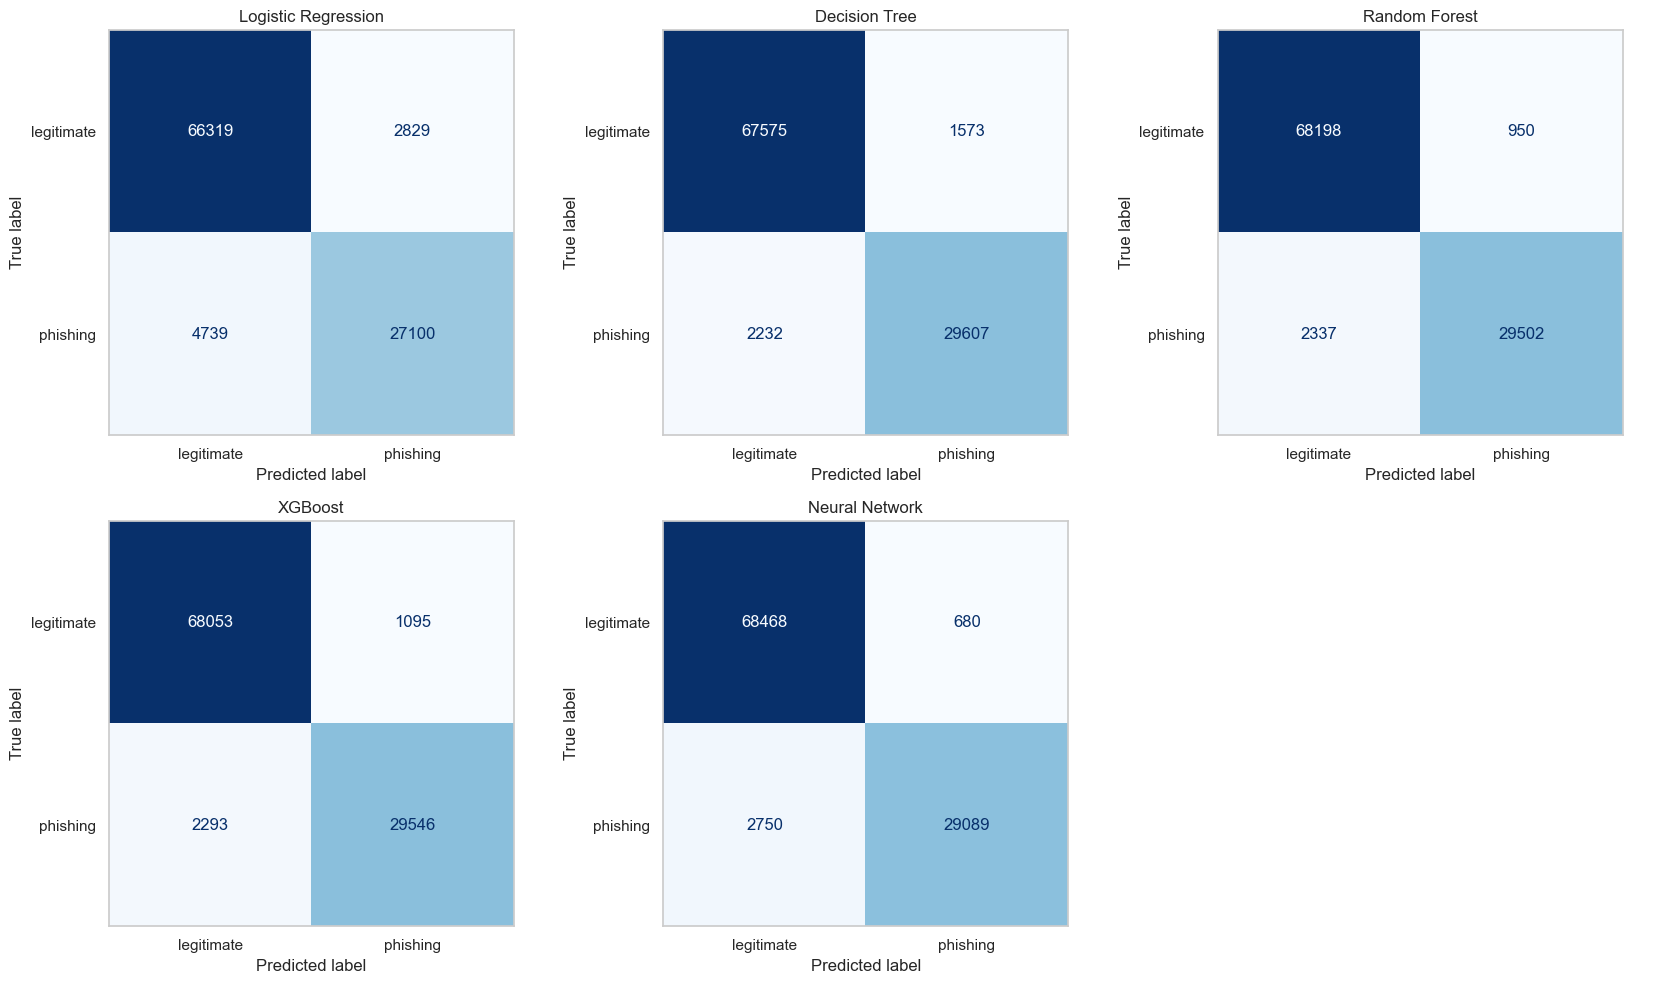

In [36]:
model_predictions = {
    "Logistic Regression": log_pred,
    "Decision Tree": tree_pred,
    "Random Forest": forest_pred,
    "XGBoost": xgb_pred,
    "Neural Network": nn_pred
}

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

for ax, (name, pred) in zip(axes, model_predictions.items()):
    matrix = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(name)
    ax.grid(False)

# Five models are shown, so the sixth panel is left empty
axes[-1].axis("off")

plt.tight_layout()
plt.show()

## **ROC Curves**

**Purpose:** Plot the true positive rate against the false positive rate for every model. A curve closer to the top left corner means a better model. The dashed line shows random guessing.

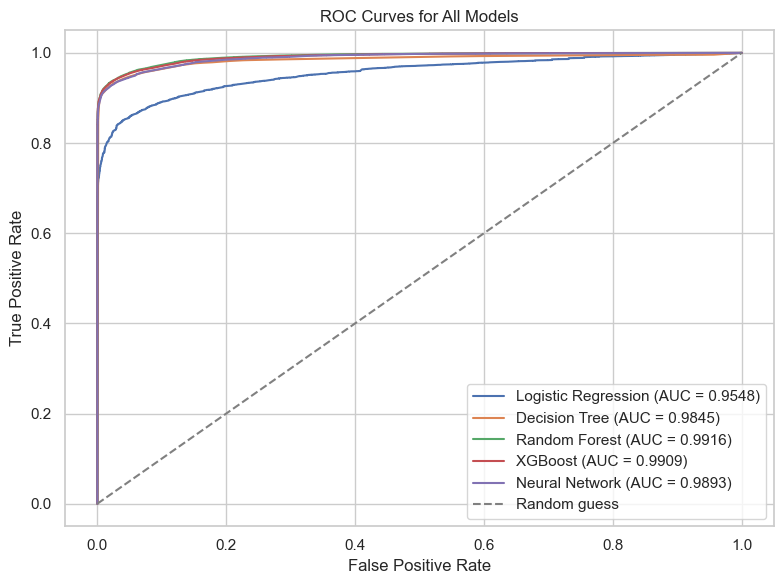

In [37]:
model_probabilities = {
    "Logistic Regression": log_prob,
    "Decision Tree": tree_prob,
    "Random Forest": forest_prob,
    "XGBoost": xgb_prob,
    "Neural Network": nn_prob
}

plt.figure(figsize=(8, 6))

for name, prob in model_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")
plt.title("ROC Curves for All Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

## **Compare Model Performance**

**Purpose:** Show all five metrics side by side in one bar chart so the models are easy to compare.

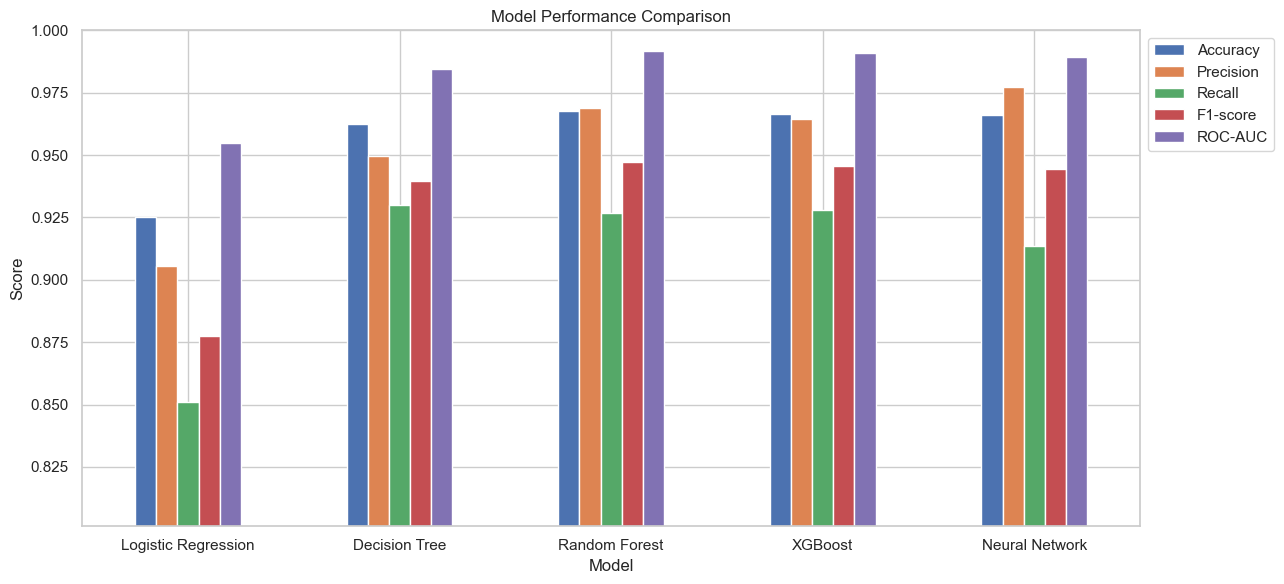

In [38]:
results.plot(kind="bar", figsize=(13, 6))
plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(results.values.min() - 0.05, 1.0)
plt.xticks(rotation=0)
plt.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

## **Identify the Best Baseline Model**

**Purpose:** Find the model with the highest score for each metric. The **F1-score** is used as the main metric because it balances catching phishing URLs and avoiding false alarms.

In [39]:
print("Best model for each metric:")
display(results.idxmax().to_frame("Best Model"))

best_model_name = results["F1-score"].idxmax()
print("Best overall model based on F1-score:", best_model_name)
display(results.loc[[best_model_name]])

Best model for each metric:


,Best Model
Accuracy,Random Forest
Precision,Neural Network
Recall,Decision Tree
F1-score,Random Forest
ROC-AUC,Random Forest


Best overall model based on F1-score: Random Forest


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest,0.9675,0.9688,0.9266,0.9472,0.9916


## **Random Forest Feature Importance**

**Purpose:** Show which features the Random Forest relied on most. This is the built in importance from the baseline model.

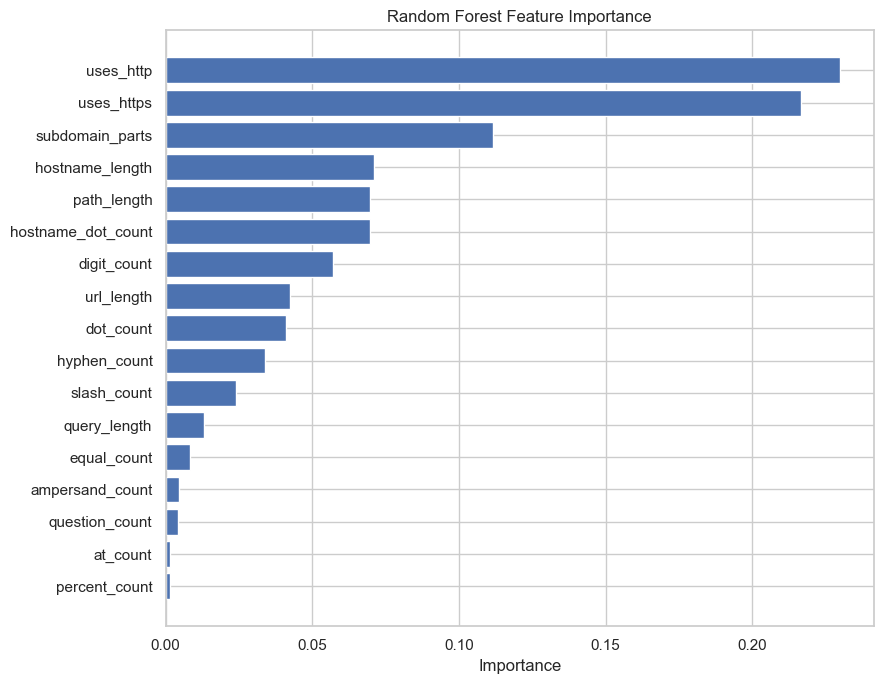

In [40]:
forest_importance = pd.Series(forest_model.feature_importances_, index=feature_columns).sort_values()

plt.figure(figsize=(9, 7))
plt.barh(forest_importance.index, forest_importance.values)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# **Second Training: Hyperparameter Tuning**

In the first training every model used fixed starting settings. In this second training the settings of each model are **tuned**, which means several combinations are tried and the best one is kept.

### **How the Tuning Works**

- **Grid search** tries every combination in a small list of settings. It is used for Logistic Regression and the Decision Tree.
- **Randomised search** tries a fixed number of random combinations from a larger list. It is used for the Random Forest, XGBoost and the Neural Network, where trying every combination would take too long.
- Each combination is scored with **3-fold stratified cross-validation**. The data is split into three parts, the model is trained on two parts and checked on the third, and this is repeated three times.
- The **F1-score** for the phishing class is used to pick the best settings, because it is the main metric in this project.
- The **test set is not used** during tuning. It is kept for the final evaluation only.

## **Create a Tuning Sample**

**Purpose:** Tuning trains each model many times, so it is run on a stratified sample of 100,000 training URLs to keep the running time reasonable. The sample keeps the same share of phishing and legitimate URLs. After the best settings are found, each model is retrained on the **full** training set.

In [41]:
X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train,
    train_size=100000,
    random_state=42,
    stratify=y_train
)

print("Tuning sample shape:", X_tune.shape)
print("\nTuning sample label percentages:")
display((y_tune.value_counts(normalize=True) * 100).round(2))

Tuning sample shape: (100000, 17)

Tuning sample label percentages:


label
0    68.47
1    31.53
Name: proportion, dtype: float64

## **Set Up Cross-Validation**

**Purpose:** Define the 3-fold stratified split that every search uses, so all models are tuned in the same way.

In [42]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

print("Cross-validation folds:", cv.get_n_splits())

Cross-validation folds: 3


## **Tune Logistic Regression**

**Purpose:** Use grid search to find the best regularisation strength `C` and to check whether balanced class weights help. The scaler and the model are joined in a pipeline, so the scaler is fitted again inside every fold and no information leaks from the validation part.

In [43]:
log_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

log_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": ["balanced", None]
}

log_search = GridSearchCV(log_pipeline, log_grid, scoring="f1", cv=cv, n_jobs=-1)
log_search.fit(X_tune, y_tune)

print("Combinations tried:", len(log_search.cv_results_["params"]))
print("Best settings:", log_search.best_params_)
print("Best cross-validated F1-score:", round(log_search.best_score_, 4))

Combinations tried: 10
Best settings: {'model__C': 10, 'model__class_weight': 'balanced'}
Best cross-validated F1-score: 0.8773


## **Tune Decision Tree**

**Purpose:** Use grid search to find the best tree depth, the minimum number of URLs in a leaf and the split criterion.

In [44]:
tree_grid = {
    "max_depth": [10, 15, 20, 25, None],
    "min_samples_leaf": [1, 5, 10],
    "criterion": ["gini", "entropy"]
}

tree_search = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=42),
    tree_grid, scoring="f1", cv=cv, n_jobs=-1
)
tree_search.fit(X_tune, y_tune)

print("Combinations tried:", len(tree_search.cv_results_["params"]))
print("Best settings:", tree_search.best_params_)
print("Best cross-validated F1-score:", round(tree_search.best_score_, 4))

Combinations tried: 30
Best settings: {'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 1}
Best cross-validated F1-score: 0.9344


## **Tune Random Forest**

**Purpose:** Use randomised search to try 10 random combinations of the number of trees, the tree depth, the leaf size and the number of features checked at each split.

In [45]:
forest_space = {
    "n_estimators": [100, 200, 300],
    "max_depth": [15, 20, 30, None],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", "log2", 0.5]
}

forest_search = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=42),
    forest_space, n_iter=10, scoring="f1", cv=cv, random_state=42
)
forest_search.fit(X_tune, y_tune)

print("Combinations tried:", len(forest_search.cv_results_["params"]))
print("Best settings:", forest_search.best_params_)
print("Best cross-validated F1-score:", round(forest_search.best_score_, 4))

Combinations tried: 10
Best settings: {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None}
Best cross-validated F1-score: 0.9435


## **Tune XGBoost**

**Purpose:** Use randomised search to try 15 random combinations of the number of trees, the tree depth, the learning rate and the row and column sampling rates.

In [46]:
xgb_space = {
    "n_estimators": [200, 300, 500],
    "max_depth": [4, 6, 8, 10],
    "learning_rate": [0.03, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "min_child_weight": [1, 3, 5]
}

xgb_search = RandomizedSearchCV(
    XGBClassifier(
        scale_pos_weight=imbalance_ratio,
        eval_metric="logloss",
        n_jobs=-1,
        random_state=42
    ),
    xgb_space, n_iter=15, scoring="f1", cv=cv, random_state=42
)
xgb_search.fit(X_tune, y_tune)

print("Combinations tried:", len(xgb_search.cv_results_["params"]))
print("Best settings:", xgb_search.best_params_)
print("Best cross-validated F1-score:", round(xgb_search.best_score_, 4))

Combinations tried: 15
Best settings: {'subsample': 0.85, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.85}
Best cross-validated F1-score: 0.9442


## **Tune Neural Network**

**Purpose:** Use randomised search to try 8 random combinations of the hidden layer sizes, the regularisation strength `alpha`, the starting learning rate and the batch size. As with Logistic Regression, the scaler and the network are joined in a pipeline.

In [47]:
nn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        max_iter=100,
        early_stopping=True,
        n_iter_no_change=5,
        random_state=42
    ))
])

nn_space = {
    "model__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64), (128, 64, 32)],
    "model__alpha": [0.00001, 0.0001, 0.001],
    "model__learning_rate_init": [0.001, 0.005, 0.01],
    "model__batch_size": [256, 512]
}

nn_search = RandomizedSearchCV(
    nn_pipeline, nn_space, n_iter=8, scoring="f1", cv=cv, n_jobs=-1, random_state=42
)
nn_search.fit(X_tune, y_tune)

print("Combinations tried:", len(nn_search.cv_results_["params"]))
print("Best settings:", nn_search.best_params_)
print("Best cross-validated F1-score:", round(nn_search.best_score_, 4))

Combinations tried: 8
Best settings: {'model__learning_rate_init': 0.01, 'model__hidden_layer_sizes': (128, 64), 'model__batch_size': 512, 'model__alpha': 1e-05}
Best cross-validated F1-score: 0.9414


## **Best Settings Found**

**Purpose:** Collect the best settings and the best cross-validated F1-score of every model in one table.

In [48]:
searches = {
    "Logistic Regression": log_search,
    "Decision Tree": tree_search,
    "Random Forest": forest_search,
    "XGBoost": xgb_search,
    "Neural Network": nn_search
}

tuning_summary = pd.DataFrame([
    {
        "Model": name,
        "Search type": type(search).__name__,
        "Combinations tried": len(search.cv_results_["params"]),
        "Best CV F1-score": round(search.best_score_, 4),
        "Best settings": {key.replace("model__", ""): value for key, value in search.best_params_.items()}
    }
    for name, search in searches.items()
]).set_index("Model")

with pd.option_context("display.max_colwidth", None):
    display(tuning_summary)

,Search type,Combinations tried,Best CV F1-score,Best settings
Model,,,,
Logistic Regression,GridSearchCV,10,0.8773,"{'C': 10, 'class_weight': 'balanced'}"
Decision Tree,GridSearchCV,30,0.9344,"{'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 1}"
Random Forest,RandomizedSearchCV,10,0.9435,"{'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None}"
XGBoost,RandomizedSearchCV,15,0.9442,"{'subsample': 0.85, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.85}"
Neural Network,RandomizedSearchCV,8,0.9414,"{'learning_rate_init': 0.01, 'hidden_layer_sizes': (128, 64), 'batch_size': 512, 'alpha': 1e-05}"


## **Retrain the Tuned Models on the Full Training Set**

**Purpose:** Take the best settings of each model and train a fresh copy on all of the training data, not only the tuning sample. The Logistic Regression and Neural Network models are pipelines, so they scale the features themselves.

In [49]:
tuned_log = clone(log_search.best_estimator_).fit(X_train, y_train)
print("Tuned Logistic Regression trained")

tuned_tree = clone(tree_search.best_estimator_).fit(X_train, y_train)
print("Tuned Decision Tree trained")

tuned_forest = clone(forest_search.best_estimator_).fit(X_train, y_train)
print("Tuned Random Forest trained")

tuned_xgb = clone(xgb_search.best_estimator_).fit(X_train, y_train)
print("Tuned XGBoost trained")

tuned_nn = clone(nn_search.best_estimator_).fit(X_train, y_train)
print("Tuned Neural Network trained")

Tuned Logistic Regression trained
Tuned Decision Tree trained
Tuned Random Forest trained
Tuned XGBoost trained
Tuned Neural Network trained


# **Second Results: Tuned Model Evaluation**

This section gives the second set of results. The tuned models are tested on the same unseen test set as the baseline models, with the same five metrics, so the two sets of results can be compared directly.

## **Make Predictions with the Tuned Models**

**Purpose:** Get the predicted class and the predicted phishing probability from each tuned model. All tuned models take the original test data, because the two pipelines scale it internally.

In [50]:
tuned_models = {
    "Logistic Regression": tuned_log,
    "Decision Tree": tuned_tree,
    "Random Forest": tuned_forest,
    "XGBoost": tuned_xgb,
    "Neural Network": tuned_nn
}

tuned_predictions = {}
tuned_probabilities = {}

for name, model in tuned_models.items():
    tuned_predictions[name] = model.predict(X_test)
    tuned_probabilities[name] = model.predict_proba(X_test)[:, 1]

print("Predictions created for all tuned models")

Predictions created for all tuned models


## **Calculate Metrics for the Tuned Models**

**Purpose:** Use the same `get_metrics` function as before and collect the tuned results in one table.

In [51]:
tuned_results = pd.DataFrame([
    get_metrics(name, y_test, tuned_predictions[name], tuned_probabilities[name])
    for name in tuned_models
])

tuned_results = tuned_results.set_index("Model").round(4)
display(tuned_results)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.9252,0.9055,0.8515,0.8777,0.9549
Decision Tree,0.9626,0.9491,0.9313,0.9401,0.9862
Random Forest,0.9684,0.9686,0.9301,0.9489,0.9924
XGBoost,0.9668,0.9647,0.9288,0.9464,0.9914
Neural Network,0.9668,0.9796,0.9137,0.9455,0.9902


## **Compare Baseline and Tuned Results**

**Purpose:** Put the baseline and tuned scores side by side and show how much each metric changed. A positive change means tuning improved the model and a negative change means the baseline settings were already better for that metric.

In [52]:
comparison = pd.concat({"Baseline": results, "Tuned": tuned_results}, axis=1)
print("Baseline and tuned results:")
display(comparison)

change = (tuned_results - results).round(4)
print("Change after tuning (tuned minus baseline):")
display(change)

Baseline and tuned results:


Baseline                                       Tuned  \
                    Accuracy Precision  Recall F1-score ROC-AUC Accuracy   
Model                                                                      
Logistic Regression   0.9251    0.9055  0.8512   0.8775  0.9548   0.9252   
Decision Tree         0.9623    0.9496  0.9299   0.9396  0.9845   0.9626   
Random Forest         0.9675    0.9688  0.9266   0.9472  0.9916   0.9684   
XGBoost               0.9665    0.9643  0.9280   0.9458  0.9909   0.9668   
Neural Network        0.9660    0.9772  0.9136   0.9443  0.9893   0.9668   

                                                        
                    Precision  Recall F1-score ROC-AUC  
Model                                                   
Logistic Regression    0.9055  0.8515   0.8777  0.9549  
Decision Tree          0.9491  0.9313   0.9401  0.9862  
Random Forest          0.9686  0.9301   0.9489  0.9924  
XGBoost                0.9647  0.9288   0.9464  0.9914  
Neural Network         0.9796  0.9137   0.9455  0.9902

Change after tuning (tuned minus baseline):


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.0001,0.0000,0.0003,0.0002,0.0001
Decision Tree,0.0003,-0.0005,0.0014,0.0005,0.0017
Random Forest,0.0009,-0.0002,0.0035,0.0017,0.0008
XGBoost,0.0003,0.0004,0.0008,0.0006,0.0005
Neural Network,0.0008,0.0024,0.0001,0.0012,0.0009


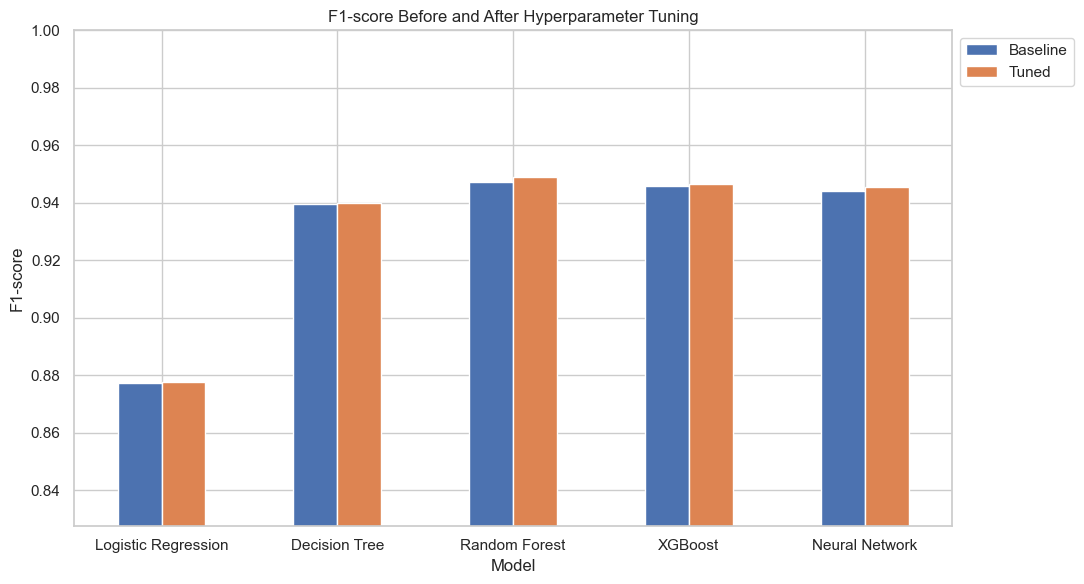

In [53]:
f1_comparison = pd.DataFrame({
    "Baseline": results["F1-score"],
    "Tuned": tuned_results["F1-score"]
})

f1_comparison.plot(kind="bar", figsize=(11, 6))
plt.title("F1-score Before and After Hyperparameter Tuning")
plt.xlabel("Model")
plt.ylabel("F1-score")
plt.ylim(f1_comparison.values.min() - 0.05, 1.0)
plt.xticks(rotation=0)
plt.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

## **Classification Reports for the Tuned Models**

**Purpose:** Show precision, recall and F1-score separately for the legitimate class and the phishing class.

In [54]:
for name, pred in tuned_predictions.items():
    print("Tuned", name)
    print(classification_report(y_test, pred, target_names=class_names, digits=4))

Tuned Logistic Regression
              precision    recall  f1-score   support

  legitimate     0.9335    0.9591    0.9461     69148
    phishing     0.9055    0.8515    0.8777     31839

    accuracy                         0.9252    100987
   macro avg     0.9195    0.9053    0.9119    100987
weighted avg     0.9246    0.9252    0.9245    100987

Tuned Decision Tree
              precision    recall  f1-score   support

  legitimate     0.9687    0.9770    0.9728     69148
    phishing     0.9491    0.9313    0.9401     31839

    accuracy                         0.9626    100987
   macro avg     0.9589    0.9542    0.9565    100987
weighted avg     0.9625    0.9626    0.9625    100987

Tuned Random Forest
              precision    recall  f1-score   support

  legitimate     0.9684    0.9861    0.9772     69148
    phishing     0.9686    0.9301    0.9489     31839

    accuracy                         0.9684    100987
   macro avg     0.9685    0.9581    0.9631    100987
weighted

## **Confusion Matrices for the Tuned Models**

**Purpose:** Show how many URLs each tuned model classified correctly and incorrectly. The matrices are read in the same way as the baseline matrices.

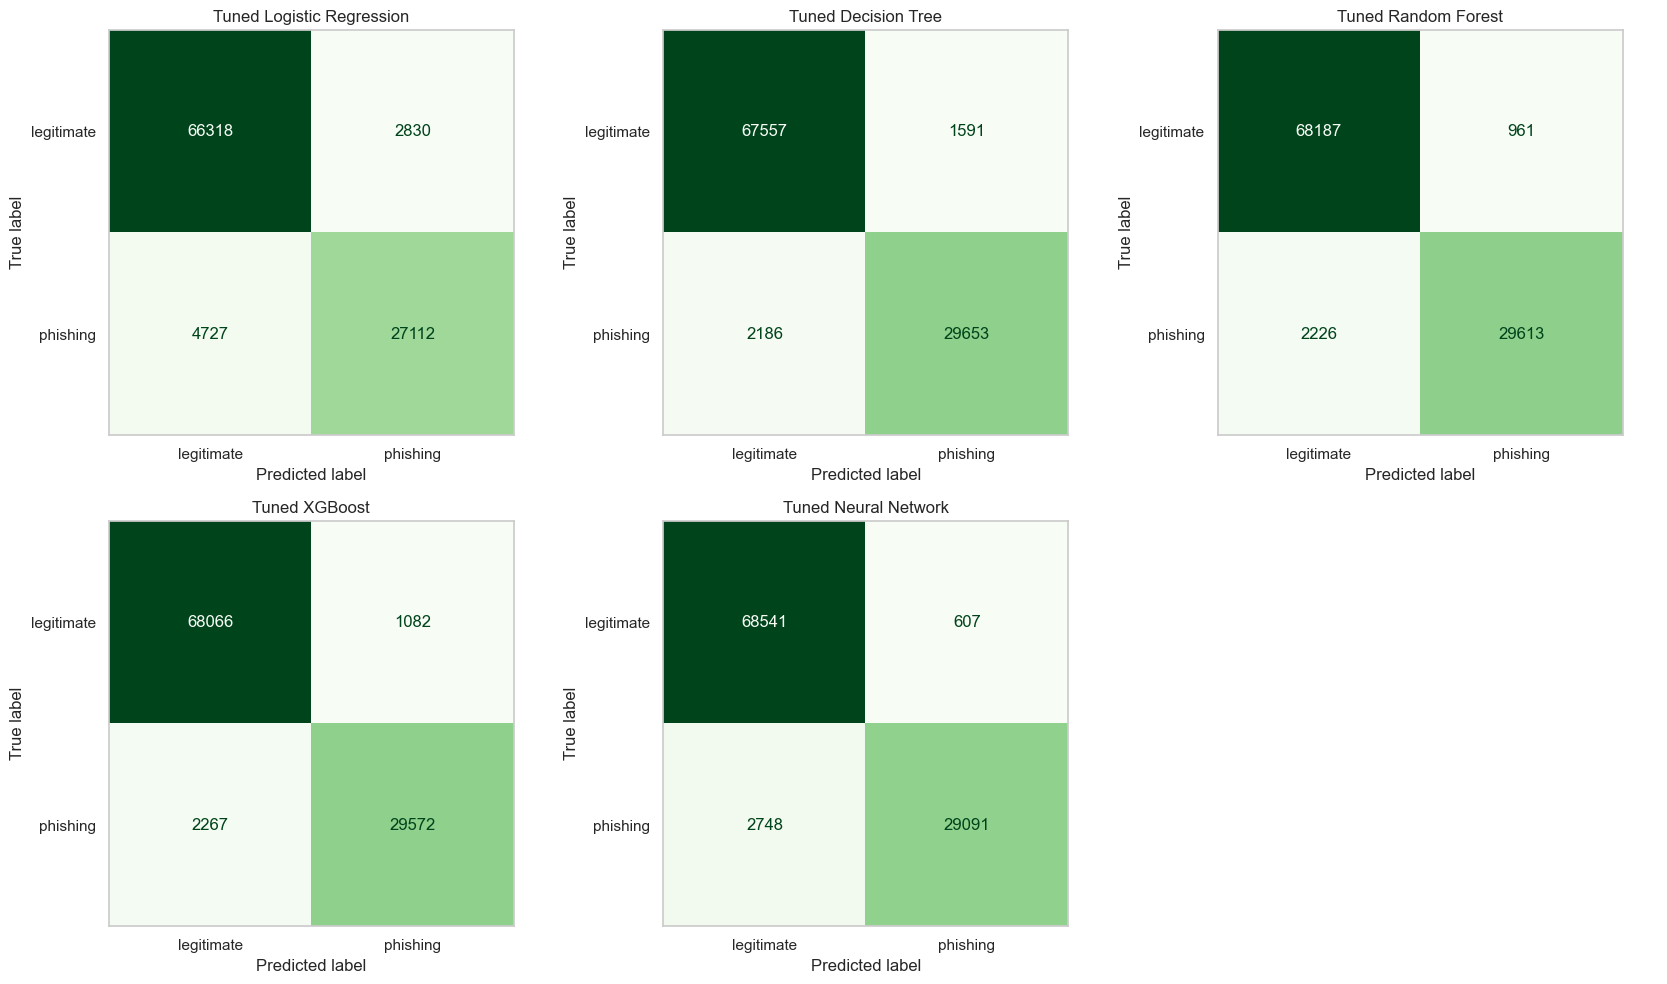

In [55]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

for ax, (name, pred) in zip(axes, tuned_predictions.items()):
    matrix = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(ax=ax, cmap="Greens", values_format="d", colorbar=False)
    ax.set_title("Tuned " + name)
    ax.grid(False)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

## **ROC Curves for the Tuned Models**

**Purpose:** Plot the ROC curve of every tuned model on the test set.

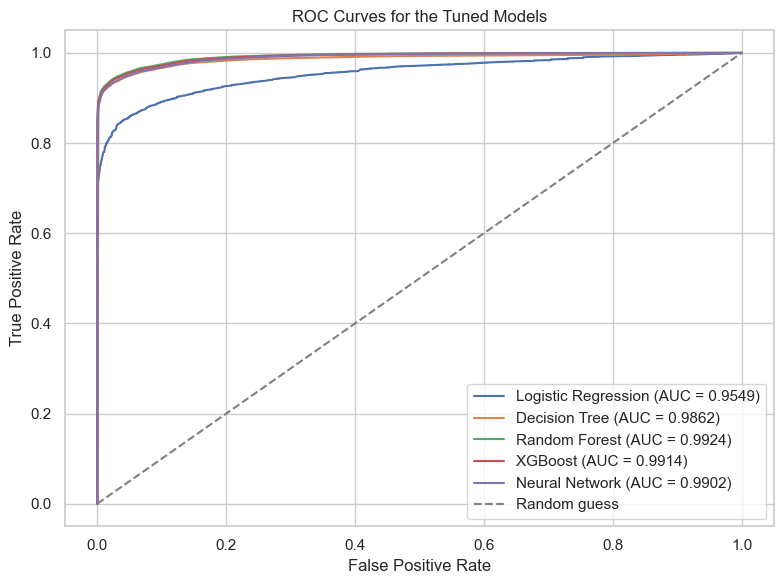

In [56]:
plt.figure(figsize=(8, 6))

for name, prob in tuned_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")
plt.title("ROC Curves for the Tuned Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

## **Identify the Best Model Overall**

**Purpose:** Rank all ten models, baseline and tuned, by F1-score. This answers the **third** research question.

In [57]:
all_results = pd.concat([
    results.rename(index=lambda name: name + " (baseline)"),
    tuned_results.rename(index=lambda name: name + " (tuned)")
]).sort_values("F1-score", ascending=False)

display(all_results)

print("Best tuned model for each metric:")
display(tuned_results.idxmax().to_frame("Best Tuned Model"))

print("Best model overall based on F1-score:", all_results.index[0])

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest (tuned),0.9684,0.9686,0.9301,0.9489,0.9924
Random Forest (baseline),0.9675,0.9688,0.9266,0.9472,0.9916
XGBoost (tuned),0.9668,0.9647,0.9288,0.9464,0.9914
XGBoost (baseline),0.9665,0.9643,0.9280,0.9458,0.9909
Neural Network (tuned),0.9668,0.9796,0.9137,0.9455,0.9902
Neural Network (baseline),0.9660,0.9772,0.9136,0.9443,0.9893
Decision Tree (tuned),0.9626,0.9491,0.9313,0.9401,0.9862
Decision Tree (baseline),0.9623,0.9496,0.9299,0.9396,0.9845
Logistic Regression (tuned),0.9252,0.9055,0.8515,0.8777,0.9549


Best tuned model for each metric:


,Best Tuned Model
Accuracy,Random Forest
Precision,Neural Network
Recall,Decision Tree
F1-score,Random Forest
ROC-AUC,Random Forest


Best model overall based on F1-score: Random Forest (tuned)


# **SHAP Explanations**

This section answers the **second** research question. SHAP (SHapley Additive exPlanations) shows how much each URL feature pushed a prediction towards phishing or towards legitimate.

### **How to Read SHAP Values**

- A **positive** SHAP value pushes the prediction towards **phishing**.
- A **negative** SHAP value pushes the prediction towards **legitimate**.
- The **larger** the value in either direction, the stronger the effect of that feature.
- The values are in **log-odds**, which is the raw output of XGBoost before it is turned into a probability.

SHAP is applied to the **tuned XGBoost** model, because `TreeExplainer` calculates exact SHAP values for tree boosting models quickly.

## **Calculate SHAP Values**

**Purpose:** Create the explainer and calculate SHAP values for a random sample of 5,000 test URLs. A sample is used so the plots stay readable and quick to draw.

In [58]:
X_shap = X_test.sample(n=5000, random_state=42)

explainer = shap.TreeExplainer(tuned_xgb)
shap_values = explainer(X_shap)

print("URLs explained:", shap_values.values.shape[0])
print("Features explained:", shap_values.values.shape[1])

URLs explained: 5000
Features explained: 17


## **Global Feature Importance**

**Purpose:** Rank the features by their mean absolute SHAP value. This shows which URL characteristics matter most to the model overall.

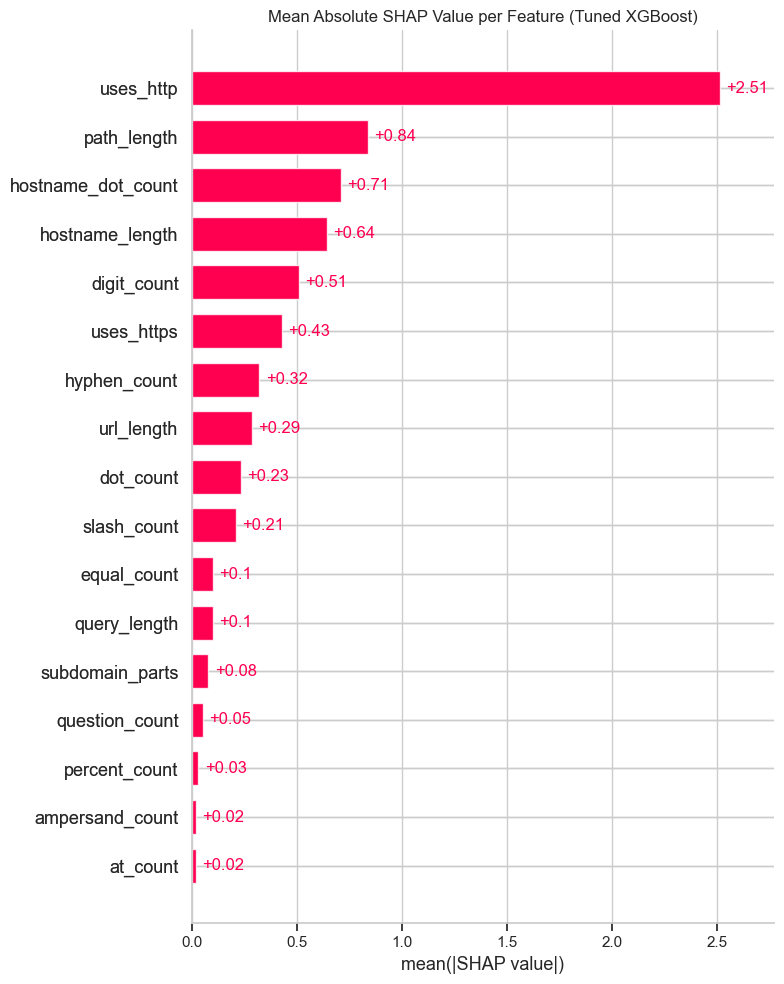

In [59]:
shap.plots.bar(shap_values, max_display=len(feature_columns), show=False)
plt.title("Mean Absolute SHAP Value per Feature (Tuned XGBoost)")
plt.tight_layout()
plt.show()

In [60]:
shap_importance = pd.DataFrame({
    "Mean absolute SHAP value": np.abs(shap_values.values).mean(axis=0)
}, index=feature_columns).sort_values("Mean absolute SHAP value", ascending=False)

shap_importance["Rank"] = range(1, len(shap_importance) + 1)
display(shap_importance.round(4))

,Mean absolute SHAP value,Rank
uses_http,2.5135,1
path_length,0.8376,2
hostname_dot_count,0.7080,3
hostname_length,0.6428,4
digit_count,0.5110,5
uses_https,0.4273,6
hyphen_count,0.3220,7
url_length,0.2875,8
dot_count,0.2330,9
slash_count,0.2083,10


## **SHAP Summary Plot**

**Purpose:** Show the direction of each feature's effect. Every dot is one URL. Red dots are high feature values and blue dots are low feature values. Dots to the right pushed the prediction towards phishing and dots to the left pushed it towards legitimate.

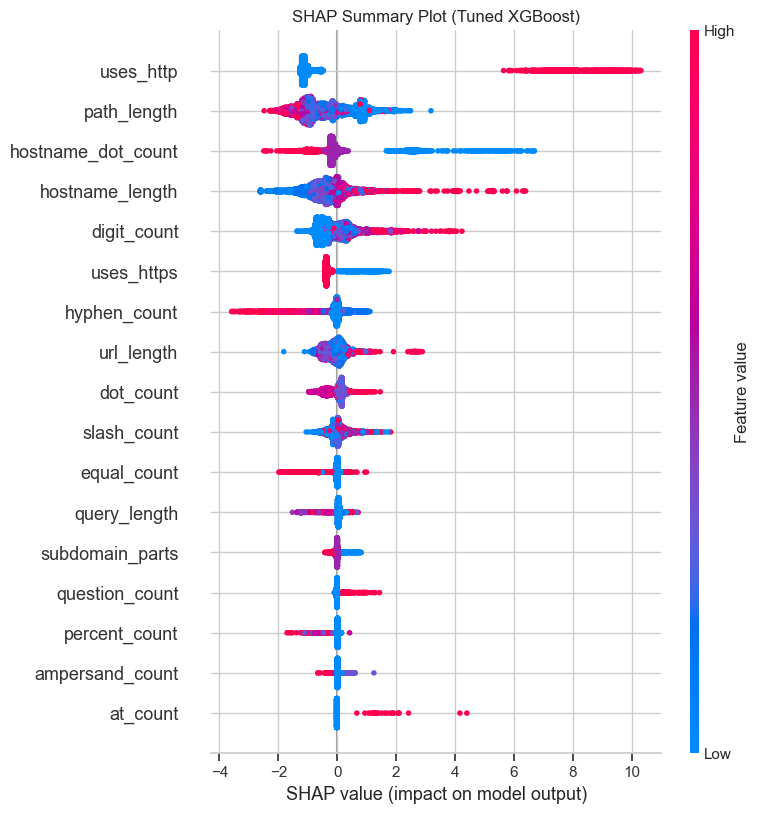

In [61]:
shap.plots.beeswarm(shap_values, max_display=len(feature_columns), show=False)
plt.title("SHAP Summary Plot (Tuned XGBoost)")
plt.tight_layout()
plt.show()

## **SHAP Dependence Plots for the Top Features**

**Purpose:** Look more closely at the three most influential features. Each plot shows how the SHAP value changes as the feature value changes.

Top three features: ['uses_http', 'path_length', 'hostname_dot_count']


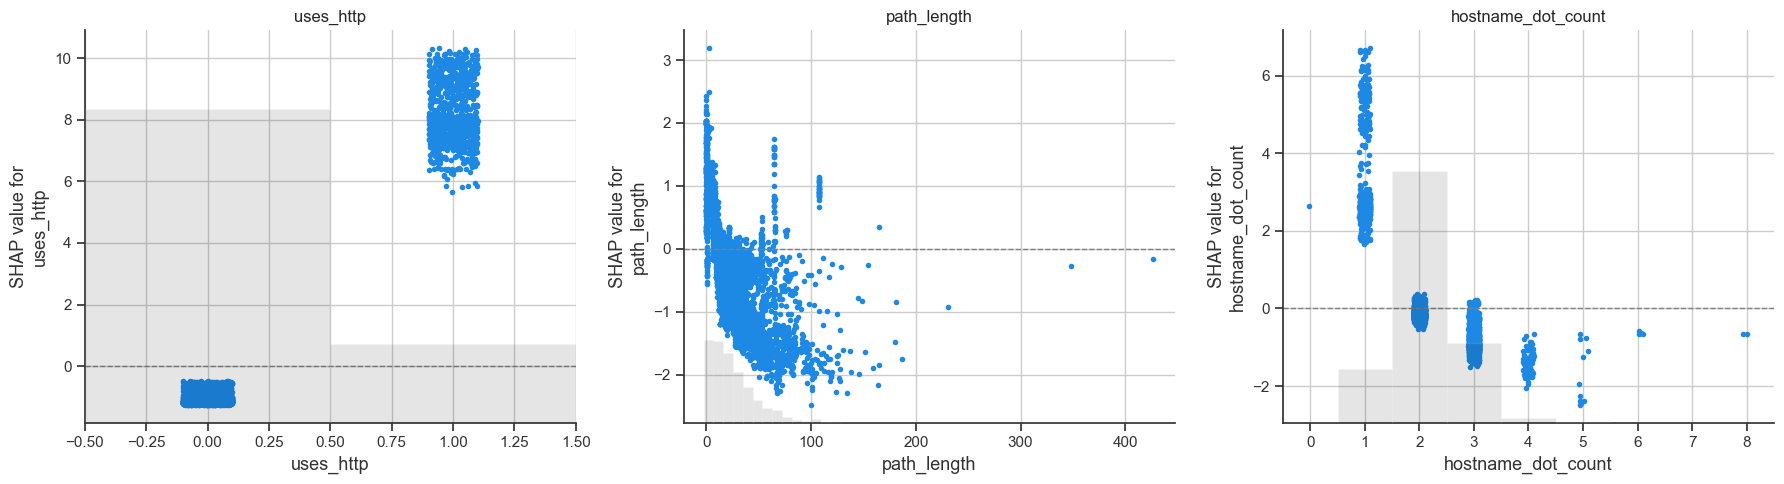

In [62]:
top_features = shap_importance.index[:3].tolist()
print("Top three features:", top_features)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, top_features):
    shap.plots.scatter(shap_values[:, feature], ax=ax, show=False)
    ax.axhline(0, color="grey", linestyle="--", linewidth=1)
    ax.set_title(feature)

plt.tight_layout()
plt.show()

## **Explain One Phishing Prediction**

**Purpose:** Explain a single URL that the model is very confident is phishing. The waterfall plot starts from the average model output and shows how each feature moved this URL's prediction up or down. The URL text itself is not printed, because the dataset contains real phishing links.

True label: phishing
Predicted phishing probability: 1.0


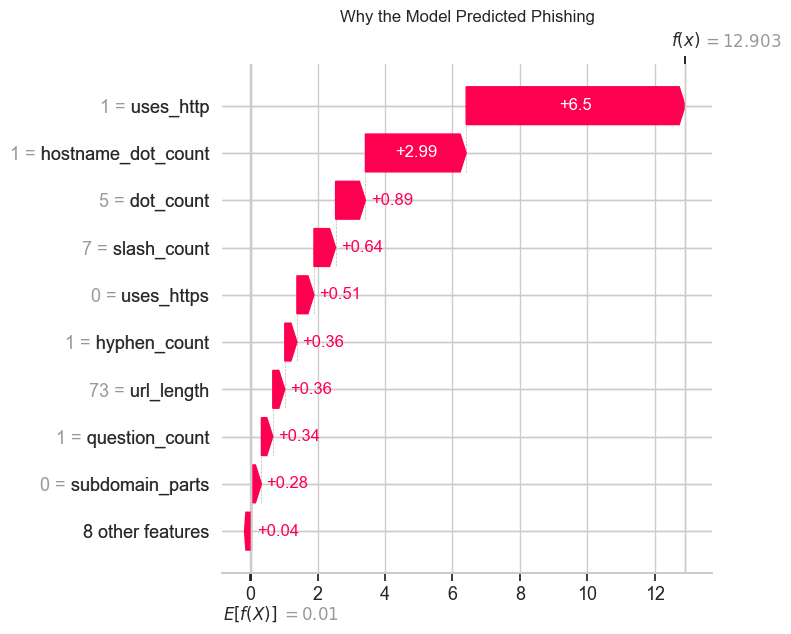

In [63]:
shap_probabilities = tuned_xgb.predict_proba(X_shap)[:, 1]
y_shap = y_test.loc[X_shap.index]

phishing_position = int(np.argmax(shap_probabilities))

print("True label:", class_names[y_shap.iloc[phishing_position]])
print("Predicted phishing probability:", round(float(shap_probabilities[phishing_position]), 4))

shap.plots.waterfall(shap_values[phishing_position], max_display=10, show=False)
plt.title("Why the Model Predicted Phishing")
plt.tight_layout()
plt.show()

## **Explain One Legitimate Prediction**

**Purpose:** Explain a single URL that the model is very confident is legitimate, to show the features that push a prediction away from phishing.

True label: legitimate
Predicted phishing probability: 0.0003


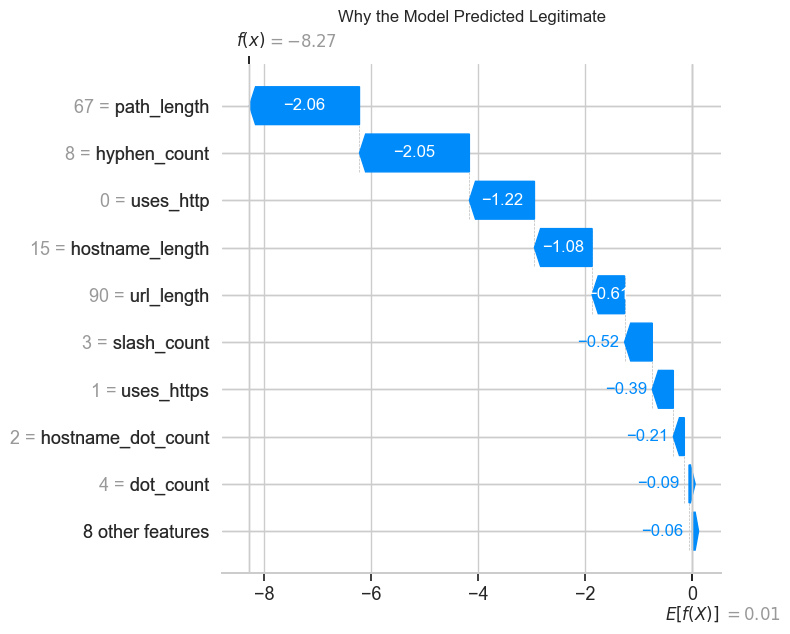

In [64]:
legitimate_position = int(np.argmin(shap_probabilities))

print("True label:", class_names[y_shap.iloc[legitimate_position]])
print("Predicted phishing probability:", round(float(shap_probabilities[legitimate_position]), 4))

shap.plots.waterfall(shap_values[legitimate_position], max_display=10, show=False)
plt.title("Why the Model Predicted Legitimate")
plt.tight_layout()
plt.show()

# **Robustness Check: Models Without Protocol Features**

The SHAP results show that `uses_http` is by far the most influential feature, and `uses_https` is also in the top six. That is a warning sign. A phishing page can use HTTPS just as easily as a normal page, so a model that leans on the protocol may be learning how this dataset was collected and not what phishing URLs look like.

This section checks how much of the performance comes from the protocol. The tuned models are trained again with the protocol information taken out, on the same training set, with the same tuned settings, and tested on the same test set.

## **Check How the Protocol Relates to the Label**

**Purpose:** Count the URLs in each protocol group and show what share of each group is phishing. This shows how strong a clue the protocol is in this dataset.

In [65]:
protocol_group = np.select(
    [df["uses_https"] == 1, df["uses_http"] == 1],
    ["https://", "http://"],
    default="no protocol"
)

protocol_table = df.groupby(protocol_group)["label"].agg(["size", "sum", "mean"])
protocol_table.columns = ["URLs", "Phishing URLs", "Phishing share (%)"]
protocol_table["Phishing share (%)"] = (protocol_table["Phishing share (%)"] * 100).round(2)

display(protocol_table)

,URLs,Phishing URLs,Phishing share (%)
http://,103659,103659,100.00
https://,401230,55528,13.84
no protocol,43,7,16.28


## **Write a Function for Retraining**

**Purpose:** The same steps are needed for each feature list, so they are put in one function. It trains a fresh copy of every tuned model on the chosen features and returns the trained models, their predictions and a results table.

In [66]:
def retrain_and_evaluate(feature_list):
    models = {}
    predictions = {}
    rows = []

    for name, model in tuned_models.items():
        models[name] = clone(model).fit(X_train[feature_list], y_train)
        predictions[name] = models[name].predict(X_test[feature_list])
        probabilities = models[name].predict_proba(X_test[feature_list])[:, 1]
        rows.append(get_metrics(name, y_test, predictions[name], probabilities))

    table = pd.DataFrame(rows).set_index("Model").round(4)
    return models, predictions, table

print("Function ready")

Function ready


## **Retrain Without the Two Protocol Features**

**Purpose:** Remove `uses_https` and `uses_http`, retrain the five tuned models and test them.

In [67]:
protocol_features = ["uses_https", "uses_http"]
reduced_features = [feature for feature in feature_columns if feature not in protocol_features]

print("Features removed:", protocol_features)
print("Features kept:", len(reduced_features))

reduced_models, reduced_predictions, reduced_results = retrain_and_evaluate(reduced_features)
display(reduced_results)

print("Change in each metric (without protocol features minus with):")
display((reduced_results - tuned_results).round(4))

Features removed: ['uses_https', 'uses_http']
Features kept: 15


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7733,0.6179,0.7365,0.6720,0.8483
Decision Tree,0.9094,0.8601,0.8511,0.8556,0.9566
Random Forest,0.9422,0.9295,0.8836,0.9060,0.9807
XGBoost,0.9251,0.8913,0.8685,0.8797,0.9721
Neural Network,0.9600,0.9709,0.9001,0.9342,0.9867


Change in each metric (without protocol features minus with):


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,-0.1519,-0.2876,-0.1150,-0.2057,-0.1066
Decision Tree,-0.0532,-0.0890,-0.0802,-0.0845,-0.0296
Random Forest,-0.0262,-0.0391,-0.0465,-0.0429,-0.0117
XGBoost,-0.0417,-0.0734,-0.0603,-0.0667,-0.0193
Neural Network,-0.0068,-0.0087,-0.0136,-0.0113,-0.0035


## **Check for Hidden Protocol Information**

**Purpose:** The models do not all fall by the same amount, and the neural network hardly falls at all. One possible reason is that the protocol can still be worked out from the other features. `url_length` counts the whole URL, including `http://` (7 characters) or `https://` (8 characters). Taking away the hostname, path and query lengths leaves the length of the protocol part. The table below tests this.

In [68]:
leftover_length = (
    df["url_length"]
    - df["hostname_length"]
    - df["path_length"]
    - df["query_length"]
    - (df["question_count"] > 0).astype(int)
)

leftover_table = pd.crosstab(leftover_length.clip(upper=10), protocol_group)
leftover_table.index.name = "Leftover length (10 means 10 or more)"
display(leftover_table)

matches_http = ((leftover_length == 7) & (df["uses_http"] == 1)).sum() / (df["uses_http"] == 1).sum()
matches_https = ((leftover_length == 8) & (df["uses_https"] == 1)).sum() / (df["uses_https"] == 1).sum()

print("http:// URLs with a leftover length of 7:", round(matches_http * 100, 2), "%")
print("https:// URLs with a leftover length of 8:", round(matches_https * 100, 2), "%")

col_0,http://,https://,no protocol
Leftover length (10 means 10 or more),,,
0,1,0,0
6,0,0,7
7,101673,0,0
8,134,400393,0
9,9,67,35
10,1842,770,1


http:// URLs with a leftover length of 7: 98.08 %
https:// URLs with a leftover length of 8: 99.79 %


## **Retrain Without Protocol Features and URL Length**

**Purpose:** Run a stricter version of the check. `url_length` is removed as well, so the protocol can no longer be worked out from the lengths. The hostname, path and query lengths stay in, so the models still know how long each part of the URL is.

In [69]:
strict_features = [feature for feature in reduced_features if feature != "url_length"]

print("Features removed:", protocol_features + ["url_length"])
print("Features kept:", len(strict_features))

strict_models, strict_predictions, strict_results = retrain_and_evaluate(strict_features)
display(strict_results)

print("Change in each metric (strict check minus all features):")
display((strict_results - tuned_results).round(4))

Features removed: ['uses_https', 'uses_http', 'url_length']
Features kept: 14


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7719,0.6156,0.7359,0.6704,0.8473
Decision Tree,0.9081,0.8609,0.8450,0.8529,0.9559
Random Forest,0.9254,0.8953,0.8644,0.8796,0.9730
XGBoost,0.9174,0.8781,0.8572,0.8675,0.9676
Neural Network,0.9214,0.9343,0.8073,0.8662,0.9649


Change in each metric (strict check minus all features):


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,-0.1533,-0.2899,-0.1156,-0.2073,-0.1076
Decision Tree,-0.0545,-0.0882,-0.0863,-0.0872,-0.0303
Random Forest,-0.0430,-0.0733,-0.0657,-0.0693,-0.0194
XGBoost,-0.0494,-0.0866,-0.0716,-0.0789,-0.0238
Neural Network,-0.0454,-0.0453,-0.1064,-0.0793,-0.0253


## **Compare the Three Feature Sets**

**Purpose:** Put the F1-score of every model side by side for all features, no protocol features, and no protocol features or URL length.

,All features,No protocol features,No protocol features or URL length
Model,,,
Logistic Regression,0.8777,0.6720,0.6704
Decision Tree,0.9401,0.8556,0.8529
Random Forest,0.9489,0.9060,0.8796
XGBoost,0.9464,0.8797,0.8675
Neural Network,0.9455,0.9342,0.8662


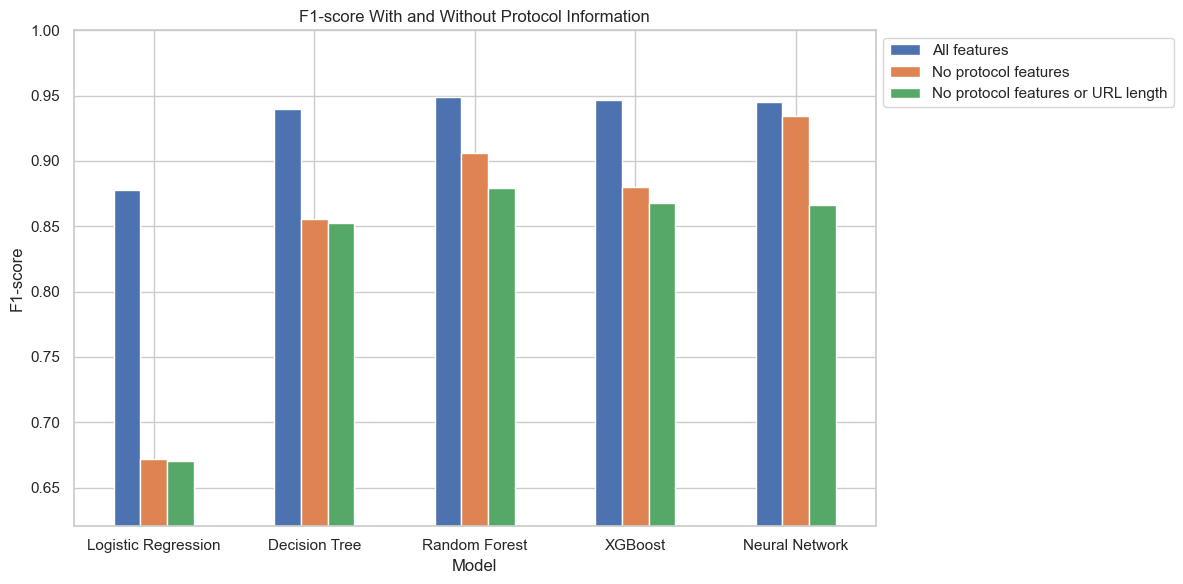

In [70]:
robustness_comparison = pd.DataFrame({
    "All features": tuned_results["F1-score"],
    "No protocol features": reduced_results["F1-score"],
    "No protocol features or URL length": strict_results["F1-score"]
})

display(robustness_comparison)

robustness_comparison.plot(kind="bar", figsize=(12, 6))
plt.title("F1-score With and Without Protocol Information")
plt.xlabel("Model")
plt.ylabel("F1-score")
plt.ylim(robustness_comparison.values.min() - 0.05, 1.0)
plt.xticks(rotation=0)
plt.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

## **Confusion Matrices for the Strict Check**

**Purpose:** See which kind of error grows once all protocol information is gone, missed phishing URLs or false alarms.

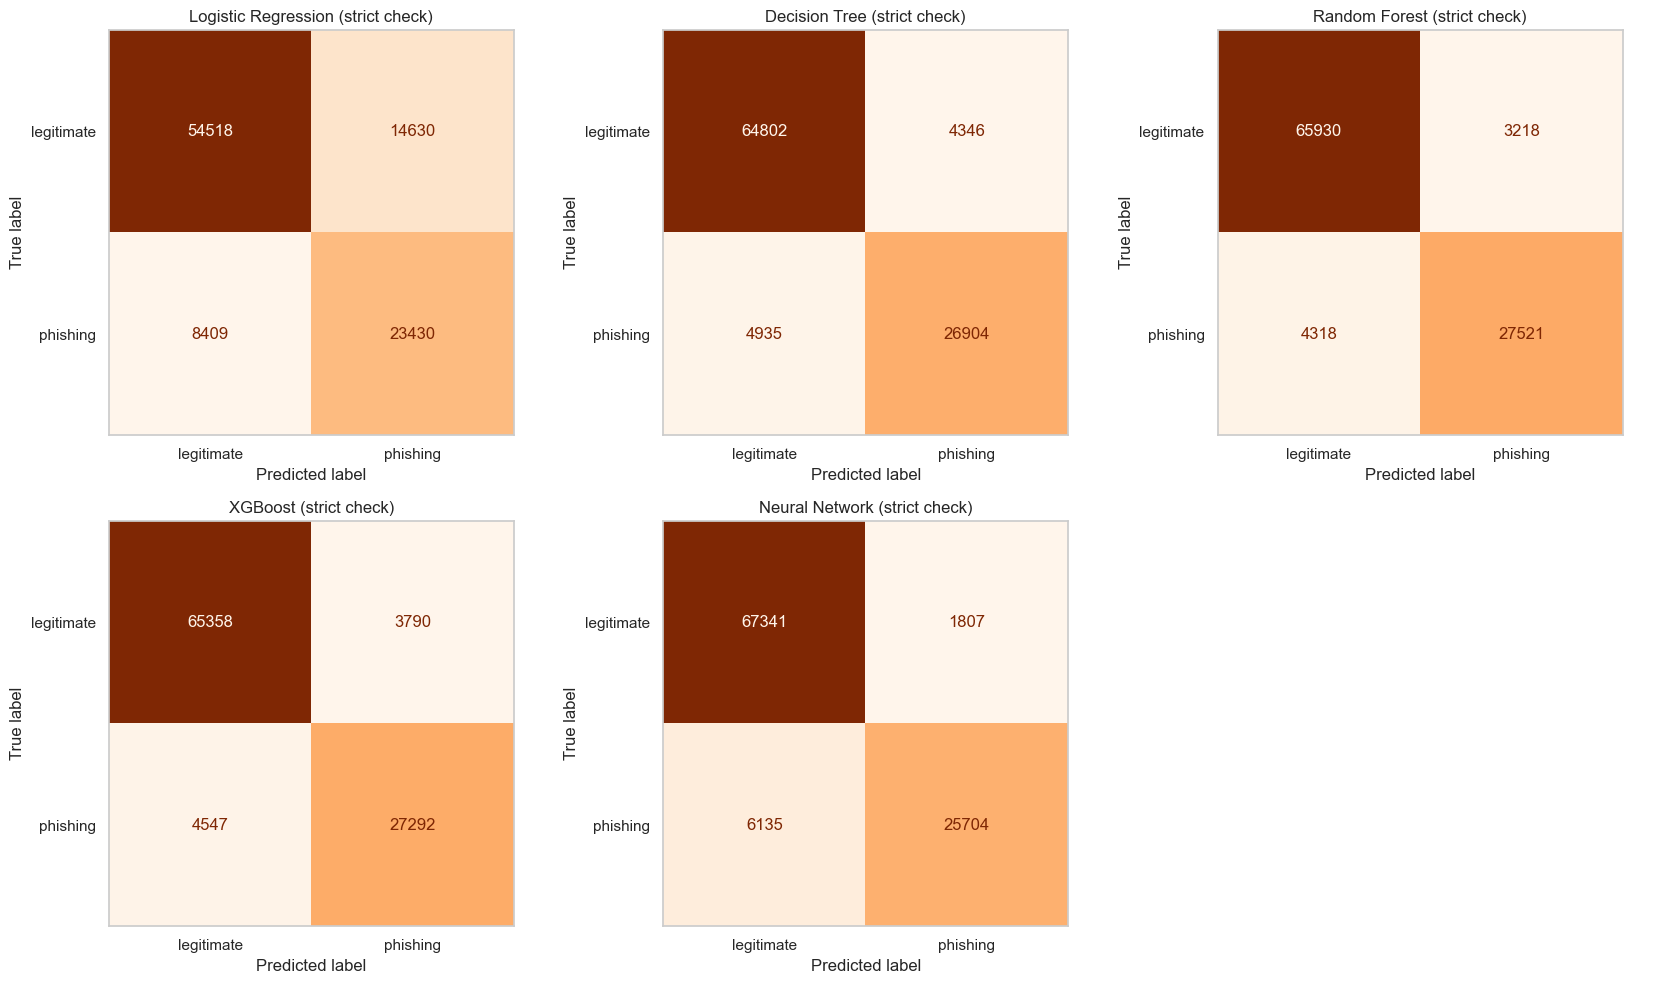

In [71]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

for ax, (name, pred) in zip(axes, strict_predictions.items()):
    matrix = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(ax=ax, cmap="Oranges", values_format="d", colorbar=False)
    ax.set_title(name + " (strict check)")
    ax.grid(False)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

## **SHAP Ranking for the Strict Check**

**Purpose:** Run SHAP again on the XGBoost model from the strict check, using the same 5,000 test URLs as before. This shows which URL characteristics the model relies on when it has no protocol information.

,Mean absolute SHAP value,Rank
hostname_dot_count,1.3411,1
path_length,0.8599,2
digit_count,0.5358,3
hostname_length,0.4643,4
slash_count,0.4487,5
hyphen_count,0.3255,6
subdomain_parts,0.2729,7
dot_count,0.2640,8
query_length,0.2098,9
equal_count,0.0880,10


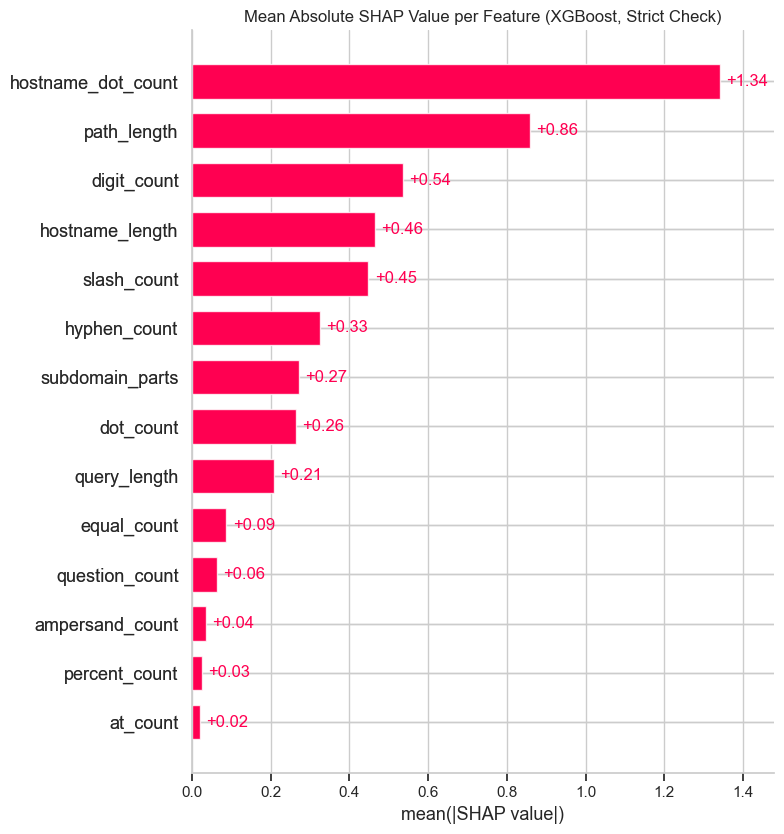

In [72]:
strict_explainer = shap.TreeExplainer(strict_models["XGBoost"])
strict_shap_values = strict_explainer(X_shap[strict_features])

strict_shap_importance = pd.DataFrame({
    "Mean absolute SHAP value": np.abs(strict_shap_values.values).mean(axis=0)
}, index=strict_features).sort_values("Mean absolute SHAP value", ascending=False)

strict_shap_importance["Rank"] = range(1, len(strict_shap_importance) + 1)
display(strict_shap_importance.round(4))

shap.plots.bar(strict_shap_values, max_display=len(strict_features), show=False)
plt.title("Mean Absolute SHAP Value per Feature (XGBoost, Strict Check)")
plt.tight_layout()
plt.show()

## **Two Further Checks on the Dataset**

**Purpose:** The strict SHAP ranking puts `hostname_dot_count` first, so the first check looks at how many URLs in each class start with `www.`, which adds one dot to the hostname. The second check counts how many test URLs come from a hostname that is also in the training set, because that affects how hard the test set is.

In [73]:
starts_with_www = df["hostname"].str.startswith("www.")
www_share = (starts_with_www.groupby(df["type"]).mean() * 100).round(2)

print("Share of URLs whose hostname starts with www. (%):")
display(www_share.to_frame("Starts with www. (%)"))

training_hostnames = set(df.loc[X_train.index, "hostname"])
test_hostname_seen = df.loc[X_test.index, "hostname"].isin(training_hostnames)

print("Test URLs with a hostname that also appears in the training set:",
      round(test_hostname_seen.mean() * 100, 2), "%")

Share of URLs whose hostname starts with www. (%):


,Starts with www. (%)
type,
legitimate,99.80
phishing,9.59


Test URLs with a hostname that also appears in the training set: 67.31 %


# **Conclusion**

This section brings the results together and answers the three research questions. All scores are from the test set of 100,987 URLs, which was kept out of training and tuning.

## **RQ1: How accurately can the classifiers separate phishing URLs from legitimate URLs?**

With all 17 features the models separate the two classes well. After tuning, the Decision Tree, Random Forest, XGBoost and Neural Network reach between 96.3% and 96.8% accuracy, with F1-scores between 0.940 and 0.949 for the phishing class. Logistic Regression is some way behind at 92.5% accuracy and an F1-score of 0.878, so a straight-line boundary does not fit these features well.

The best model is the tuned Random Forest. It got 3,187 of the 100,987 test URLs wrong: 2,226 phishing URLs were missed and 961 legitimate URLs were flagged by mistake. Missed phishing is the more common error, which matches its recall of 0.930 against a precision of 0.969.

The robustness check changes how these scores should be read. Every URL in the dataset that starts with `http://` is phishing (103,659 URLs), while only 13.84% of the `https://` URLs are. The protocol alone identifies about 65% of all phishing URLs. When `uses_https`, `uses_http` and `url_length` are removed, the best F1-score drops from 0.949 to 0.880 and the best accuracy from 96.8% to 92.5%.

So the answer to RQ1 has two parts. On this dataset as it is, the best models are right about 97% of the time. When they can only use the structure of the URL, that falls to about 92.5%. The second figure is the safer one to quote for new URLs, because a phishing page can use HTTPS as easily as any other site.

## **RQ2: Which URL characteristics does SHAP identify as most influential?**

For the tuned XGBoost model, `uses_http` is the most influential feature by a wide margin. Its mean absolute SHAP value is 2.51, three times the value of the second feature. The next five are `path_length` (0.84), `hostname_dot_count` (0.71), `hostname_length` (0.64), `digit_count` (0.51) and `uses_https` (0.43). The symbol counts for `@`, `&` and `%` sit at the bottom of the ranking because most URLs do not contain them.

The summary plot gives the direction of each effect. Starting with `http://` pushes a URL strongly towards phishing. A hostname with only one dot, a long hostname and a high number of digits also push towards phishing. A longer path and more hyphens push towards legitimate.

Once the protocol information is removed, the ranking for XGBoost is led by `hostname_dot_count` (1.34), followed by `path_length` (0.86), `digit_count` (0.54), `hostname_length` (0.46) and `slash_count` (0.45). The lexical and structural characteristics that matter most are therefore the shape of the hostname, the length of the path and the number of digits.

The hostname result needs some care. In this dataset 99.8% of the legitimate URLs start with `www.` and only 9.59% of the phishing URLs do, so part of what `hostname_dot_count` measures is this prefix. Like the protocol, it may say more about where the URLs were collected from than about phishing in general.

## **RQ3: Which model performs best?**

The tuned Random Forest performs best overall. It has the highest accuracy (0.9684), F1-score (0.9489) and ROC-AUC (0.9924). XGBoost and the Neural Network are close behind with F1-scores of 0.9464 and 0.9455. The gap between these three models is less than 0.004, which is small enough that a different train and test split could change the order.

The other two metrics point to different models. The Neural Network has the highest precision (0.9796) and raises the fewest false alarms, 607, but it misses 2,748 phishing URLs. The Decision Tree has the highest recall (0.9313). Which of these matters more depends on whether a missed phishing URL or a false alarm is the bigger problem for the user.

Tuning helped very little. The largest gain in F1-score was 0.0017, for the Random Forest, and the starting settings were already close to the best ones found. The results are limited more by the features than by the model settings.

The Random Forest also stays in first place in the strict robustness check, with an F1-score of 0.880. The Neural Network looked the most stable when only the two protocol features were removed (F1-score 0.934), but it had worked the protocol back out from the URL lengths. With `url_length` removed as well it fell to 0.866, level with XGBoost.

## **Limitations**

The main limitation is the dataset. The protocol and the `www.` prefix separate the classes far more cleanly than they would in real traffic, so the headline scores are likely to be higher than what the models would reach elsewhere. About 67% of the test URLs also share a hostname with a URL in the training set, which makes the test easier than classifying a website the model has never seen.

The models only use 17 simple counts and lengths. They do not look at the words in the URL, the top-level domain, or anything about the page behind the link. Tuning was run on a 100,000 URL sample with a small number of combinations, and all results come from one train and test split. SHAP was applied to XGBoost only, on 5,000 test URLs, so the ranking describes that model and not the Random Forest or the Neural Network.

## **Future Work**

The first step would be to repeat the experiment on data where the protocol and the `www.` prefix are balanced across the classes, or to strip both from every URL before the features are extracted. Splitting the data by hostname, so that no website appears in both the training and test sets, would give a fairer test.

The feature set could be extended with character entropy, the top-level domain and common phishing keywords. A neural network that reads the URL character by character could also be compared with the feature-based models used here.